# Berth Allocation & Scheduling: Pyomo model

OR2 course project, Phase 2. The MILP from Phase 1 is built in **Pyomo** and solved with **GLPK**.

Notebook contents:
1. Sets, parameters (read from `../data/Parameters.xlsx`), variables, objective and constraints
2. Solving the model and exporting the solution to `results/pyomo_results.xlsx`
3. Visualisations: berth schedule (Gantt chart), waiting times, extra capacity used
4. Relaxing the "exactly 3 ships at berth 3" rule and comparing results
5. Sensitivity analysis on lag time at berth 2, unloading time of ship 7 at berth 3, capacity of berths 2 and 3, and arrival time of ship 6

**Base objective:** 1803.27 &nbsp;|&nbsp; **Berth 3 relaxed:** 1605.56


In [1]:
import pyomo.environ as pyo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
from pyomo.environ import value, TerminationCondition
import seaborn as sns
import math

# Model parameters are read from the shared data folder
DATA_FILE = '../data/Parameters.xlsx'


In [2]:
model = pyo.ConcreteModel()

In [3]:
n=8
m=4
#ship sets
model.i = pyo.RangeSet(1,n)
model.q= pyo.RangeSet(1,n)
model.iq = pyo.Set(dimen=2, initialize=lambda m: [(i, q) for i in model.i for q in model.i if i != q])
#doc set
model.j= pyo.RangeSet(1,m)
# objective set
model.k = pyo.RangeSet(1,3)
model.bin = pyo.RangeSet(1, 2)
big_M = 80

<h1>Parameters</h1>

In [4]:
Containers= pd.read_excel(DATA_FILE, sheet_name='Containers', index_col=0)
Anchorage = pd.read_excel(DATA_FILE, sheet_name='Anchorage', index_col=0)
Unload_Time = pd.read_excel(DATA_FILE, sheet_name='Unload Time', index_col=0)
Capacity = pd.read_excel(DATA_FILE, sheet_name='Capacity', index_col=0)
Length = pd.read_excel(DATA_FILE, sheet_name='Length', index_col=0)
Max_length = pd.read_excel(DATA_FILE, sheet_name='Max Length', index_col=0)
Lag = pd.read_excel(DATA_FILE, sheet_name='Lag', index_col=0)
Priority = pd.read_excel(DATA_FILE, sheet_name='Priority', index_col=0)
Arrival_Time= pd.read_excel(DATA_FILE, sheet_name='Arrival Time', index_col=0)
Cost_for_Extra_Capacity= pd.read_excel(DATA_FILE, sheet_name='Cost for Extra Capacity', index_col=0)
Max_Extra_Allowable_Capacity = pd.read_excel(DATA_FILE, sheet_name='Max Extra Allowable Capacity', index_col=0)

In [5]:
df = pd.read_excel(DATA_FILE, sheet_name="Unload Time")

# Convert the 'Ship_Berth' string to a tuple of integers
df['Ship_Berth'] = df['Ship_Berth'].apply(lambda x: tuple(map(int, ast.literal_eval(x))))

# Now create the dict
unload_dict = dict(zip(df['Ship_Berth'], df['Unload_Time']))

In [6]:
model.C = pyo.Param(model.j, initialize= Capacity.loc[:,'Capacity'].to_dict(), mutable= True)
model.CA= pyo.Param(model.i, initialize= Containers.loc[:,'Containers'].to_dict(), mutable= True)
model.L= pyo.Param(model.j, initialize= Max_length.loc[:,'Max_Length'].to_dict(), mutable= True)
model.LS= pyo.Param(model.i, initialize= Length.loc[:,'Length'].to_dict(), mutable= True)
model.P= pyo.Param(model.i, initialize= Priority.loc[:,'Priority'].to_dict(), mutable= True)
model.O = pyo.Param(model.j, initialize= Lag.loc[:,'Lag'].to_dict(), mutable= True)
model.Un = pyo.Param(model.i, model.j, initialize= unload_dict, mutable= True)
model.a = pyo.Param(model.i, initialize= Arrival_Time.loc[:,'Arrival_Time'].to_dict(), mutable= True)
model.CIC = pyo.Param(model.j, initialize= Cost_for_Extra_Capacity.loc[:,'Cost for Extra Capacity'].to_dict(), mutable=True)
model.ext = pyo.Param(model.j, initialize= Max_Extra_Allowable_Capacity.loc[:,'Max Extra Allowable Capacity'].to_dict(), mutable= True)

<h1>Variables

In [7]:
model.X = pyo.Var(model.i, model.j, domain=pyo.Binary)
model.W = pyo.Var(model.i, domain= pyo.NonNegativeReals)
model.d = pyo.Var(model.i, model.j, domain= pyo.NonNegativeReals)
model.IC = pyo.Var(model.j, domain=pyo.NonNegativeIntegers)
model.y = pyo.Var(model.iq, model.j, domain= pyo.Binary)
model.u = pyo.Var(model.i, model.k, domain= pyo.NonNegativeReals)
model.f = pyo.Var(model.i, model.bin, domain=pyo.Binary)
model.s = pyo.Var(model.i, domain= pyo.NonNegativeReals)

<h1>Objective</h1>

In [8]:
def objective_function_expression(model):
  return 25*pyo.quicksum(model.u[i,1] for i in model.i) + 10 * pyo.quicksum(model.u[i,2] for i in model.i) + 5*pyo.quicksum(model.u[i,3] for i in model.i)+ 5* pyo.quicksum(model.Un[i,j] * model.X[i,j] for i in model.i for j in model.j) + pyo.quicksum(model.CIC[j]* model.IC[j] for j in model.j)
model.obj = pyo.Objective(rule= objective_function_expression, sense= pyo.minimize)

<h1> Constraints

In [9]:
def one_pier_to_ship(model, i):
  return pyo.quicksum(model.X[i,j] for j in model.j) ==1
model.c1= pyo.Constraint(model.i, rule=one_pier_to_ship)

def number_ships_to_pier(model, j):
  if j==3:
    return pyo.quicksum(model.X[i,j] for i in model.i) ==3
  else:
    return pyo.quicksum(model.X[i,j] for i in model.i) <=2
model.c2 = pyo.Constraint(model.j, rule= number_ships_to_pier)

def number_container(model, j):
  return pyo.quicksum(model.X[i,j] * model.CA[i]  for i in model.i) <= model.C[j] + model.IC[j]
model.c3 = pyo.Constraint(model.j, rule=number_container)

def capacity_ceiling(model, j):
  return model.IC[j]<= model.ext[j]
model.c4 =pyo.Constraint(model.j, rule= capacity_ceiling)

def ship_length (model, i , j):
  return model.LS[i] * model.X[i,j] <= model.L[j]
model.c5 = pyo.Constraint(model.i, model.j, rule= ship_length)

def max_wait(model, i):
  return model.W[i] <= 80*(1-model.P[i])
model.c6 = pyo.Constraint(model.i, rule=max_wait)

def equ_cons_x_and_w(model, i):
  return model.W[i] == model.s[i] - model.a[i]
model.c7 = pyo.Constraint(model.i, rule=equ_cons_x_and_w)

def not_unloading(model, i, q, j):
    if i == q:
        return pyo.Constraint.Skip
    return  model.s[i] + model.Un[i,j] + model.O[j] <= model.s[q] + big_M * (1-model.y[i, q, j])
model.c8 = pyo.Constraint(model.iq, model.j,  rule=not_unloading)

def equ_cons_y (model, i,q,j):
  if i==q:
    return pyo.Constraint.Skip
  return model.y[i,q,j]+ model.y[q,i,j]<=1
model.c9 = pyo.Constraint(model.iq, model.j, rule=equ_cons_y)


def y_one(model,i,q,j):
    if i==q:
        return pyo.Constraint.Skip
    return model.y[i,q,j] + model.y[q,i,j] >= model.X[i,j] + model.X[q,j] - 1
model.c10 = pyo.Constraint(model.iq, model.j, rule=y_one)

def y_two(model,i,q,j):
    if i==q:
        return pyo.Constraint.Skip
    return model.y[i,q,j] + model.y[q,i,j] <= model.X[i,j]
model.c11 = pyo.Constraint(model.iq, model.j, rule=y_two)


# محدودیت صفر شدن زمان انتظار اگر کشتی تنها باشد
def wait_zero_if_alone(model, i,q, j):
    if i==q:
        return pyo.Constraint.Skip
    if j==3 :
        y = pyo.quicksum(model.y[i,q,j] for q in model.q if q!= i)
        return model.W[i] <= 80 * (2- y)
    return model.W[i] <= 80 * (1 - model.y[i,q,j])
model.c13 = pyo.Constraint(model.iq, model.j, rule=wait_zero_if_alone)

def equ_cons_w_and_u (model, i):
  return model.W[i] == pyo.quicksum(model.u[i,k] for k in model.k)
model.c14 = pyo.Constraint(model.i, rule=equ_cons_w_and_u)

def equ_cons_f_and_u(model, i, bin):
  if bin == 1:
    return 10*model.f[i, bin]<= model.u[i, bin]
  elif bin == 2:
    return 30*model.f[i, bin]<= model.u[i, bin]
model.c15 = pyo.Constraint(model.i, model.bin, rule= equ_cons_f_and_u)

def equ_u(model, i, k):
  if k == 1:
    return 10 >= model.u[i, k]
  elif k == 2:
    return 30*model.f[i,1] >= model.u[i, k]
  elif k == 3:
    return 30*model.f[i,2] >= model.u[i, k]
model.c16 = pyo.Constraint(model.i, model.k, rule= equ_u)

def ff(model,i):
    return model.f[i,1] >= model.f[i,2]
model.c17 = pyo.Constraint(model.i, rule=ff)


<h1>Solver

In [10]:
solver= pyo.SolverFactory('glpk')
result = solver.solve(model, tee=False)  # set tee=True to see the full solver log
result.write()

In [11]:
if result.solver.termination_condition != TerminationCondition.infeasible:
    for i, j in model.X.index_set():
        if model.X[i, j].value > 0:
            print(f"X[{i}, {j}] = {model.X[i,j].value}")
    for i in model.W.index_set():
        if model.W[i].value >= 0:
            print(f"W[{i}] = {model.W[i].value}")
    for i in model.s.index_set():
        if model.s[i].value >= 0:
            print(f"s[{i}] = {model.s[i].value}")
            
    for i,q, j in model.y.index_set():
        if model.y[i,q,j].value == 1:
            print(f"y[{i},{q}, {j}] = {model.y[i,q,j].value}")
            
    for i,j in model.u.index_set():
        if model.u[i,j].value > 0:
            print(f"u[{i},{j}] = {model.u[i,j].value}")
            
    
    obj_val = value(model.obj)
    print(f"Objective value: {obj_val}")


X[1, 2] = 1.0
X[2, 4] = 1.0
X[3, 3] = 1.0
X[4, 1] = 1.0
X[5, 3] = 1.0
X[6, 2] = 1.0
X[7, 3] = 1.0
X[8, 4] = 1.0
W[1] = 0.0
W[2] = 0.0
W[3] = 19.2670572909898
W[4] = 0.0
W[5] = 39.3788913469807
W[6] = 20.6958212309185
W[7] = 0.0
W[8] = 8.24083515240811
s[1] = 4.76552698703798
s[2] = 1.00459250301696
s[3] = 22.9200559414305
s[4] = 6.05417812493725
s[5] = 41.2480808268544
s[6] = 22.813811450173
s[7] = 4.62295182452406
s[8] = 14.8420135358433
y[1,6, 2] = 1.0
y[2,8, 4] = 1.0
y[3,5, 3] = 1.0
y[7,3, 3] = 1.0
y[7,5, 3] = 1.0
u[3,1] = 10.0
u[3,2] = 9.26705729098979
u[5,1] = 10.0
u[5,2] = 29.3788913469807
u[6,1] = 10.0
u[6,2] = 10.6958212309185
u[8,1] = 8.24083515240811
Objective value: 1803.2706014701052


In [12]:
if result.solver.termination_condition != TerminationCondition.infeasible:
    # Export X[i, j]
    X_data = [(i, j, model.X[i, j].value) for (i, j) in model.X if model.X[i, j].value is not None and model.X[i, j].value > 0]
    df_X = pd.DataFrame(X_data, columns=['Ship', 'Dock', 'Assigned'])

    # Export W[i]
    W_data = [(i, model.W[i].value) for i in model.W if model.W[i].value is not None]
    df_W = pd.DataFrame(W_data, columns=['Ship', 'Wait_Time'])

    # Export s[i]
    s_data = [(i, model.s[i].value) for i in model.s if model.s[i].value is not None]
    df_s = pd.DataFrame(s_data, columns=['Ship', 'Start_Time'])

    # Export y[i, q, j]
    y_data = [(i, q, j, model.y[i, q, j].value) for (i, q, j) in model.y if model.y[i, q, j].value == 1]
    df_y = pd.DataFrame(y_data, columns=['Ship1', 'Ship2', 'Dock', 'y_value'])

    # Export u[i, k]
    u_data = [(i, k, model.u[i, k].value) for (i, k) in model.u if model.u[i, k].value is not None and model.u[i, k].value > 0]
    df_u = pd.DataFrame(u_data, columns=['Ship', 'Objective_K', 'u_value'])

    # Export IC[j]
    IC_data = [(j, model.IC[j].value) for j in model.IC ]
    df_IC = pd.DataFrame(IC_data, columns=['Dock', 'Extra_Capacity_Used'])

    #Exort Un[i,j]

    # Objective value
    obj_val = value(model.obj)

    df_orginal_solution = pd.concat([df_X, df_W], axis=1)
    # Save all to Excel
    with pd.ExcelWriter("results/pyomo_results.xlsx") as writer:
        df_X.to_excel(writer, sheet_name="X", index=False)
        df_W.to_excel(writer, sheet_name="W", index=False)
        df_s.to_excel(writer, sheet_name="s", index=False)
        df_y.to_excel(writer, sheet_name="y", index=False)
        df_u.to_excel(writer, sheet_name="u", index=False)
        df_IC.to_excel(writer, sheet_name="IC", index=False)

    print("Objective Value:", obj_val)
    print("Results saved to results/pyomo_results.xlsx")

Objective Value: 1803.2706014701052
Results saved to pyomo_results.xlsx


In [13]:
# Example: if Unload duration is available
df_Un = pd.DataFrame({'Ship': df_s['Ship'], 'Unload_Duration': 10})  # Replace 10 with actual Un[i,j]

priority_data = [(i, float(value(model.P[i]))) for i in model.P]
df_priority = pd.DataFrame(priority_data, columns=['Ship', 'Priority_Value'])

# Define priority levels
def classify_priority(p):
    if p > 0.9:
        return 'High'
    elif p > 0.4:
        return 'Medium'
    else:
        return 'Low'

df_priority['Priority'] = df_priority['Priority_Value'].apply(classify_priority)
# Merge everything
df_schedule = df_X.merge(df_s, on="Ship").merge(df_Un, on="Ship").merge(df_priority, on="Ship")
df_schedule['End_Time'] = df_schedule['Start_Time'] + df_schedule['Unload_Duration']

# Color mapping by priority
priority_colors = {
    'High': '#ff6b6b',     # Red
    'Medium': '#feca57',   # Orange
    'Low': '#1dd1a1'       # Green
}

df_schedule['Color'] = df_schedule['Priority'].map(priority_colors)

<h1>Visualization

<h3> Docking Schedule (Gantt Chart)

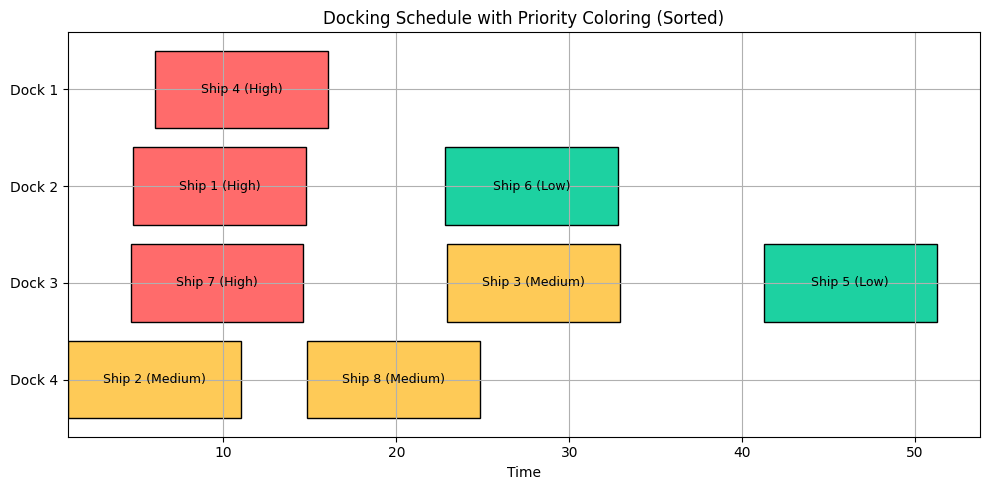

In [14]:
# Make sure dock is numeric if it isn't already
df_schedule['Dock'] = df_schedule['Dock'].astype(int)

# Sort by Dock (numerically)
df_schedule = df_schedule.sort_values(by='Dock', ascending=False)

# Create an ordered list of dock labels
dock_labels = sorted(df_schedule['Dock'].unique())
dock_labels = [f'Dock {d}' for d in dock_labels]

# === Gantt Chart with sorted docks ===
fig, ax = plt.subplots(figsize=(10, 5))
for _, row in df_schedule.iterrows():
    ax.barh(y=f'Dock {row.Dock}', left=row.Start_Time, width=row.Unload_Duration,
            color=row.Color, edgecolor='black')
    ax.text(row.Start_Time + row.Unload_Duration/2, f'Dock {row.Dock}',
            f'Ship {row.Ship} ({row.Priority})', va='center', ha='center', fontsize=9)

ax.set_yticks([f'Dock {d}' for d in sorted(df_schedule['Dock'].unique())])
ax.set_yticklabels(dock_labels)  # ensure consistent order
ax.set_xlabel("Time")
ax.set_title("Docking Schedule with Priority Coloring (Sorted)")
plt.grid(True)
plt.tight_layout()
plt.show()

<h3> Ship Wait Times with Priority Coloring

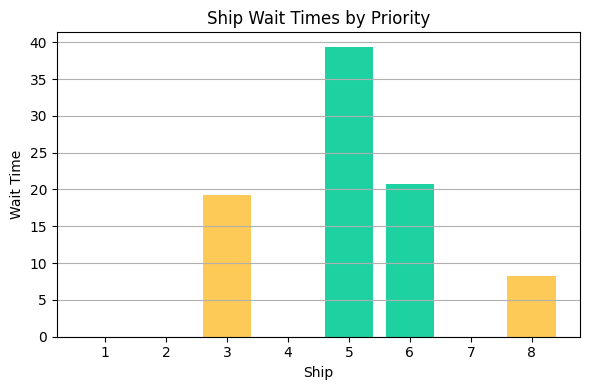

In [15]:
df_W = df_W.merge(df_priority, on="Ship")
fig, ax = plt.subplots(figsize=(6, 4))
colors = df_W['Priority'].map(priority_colors)
ax.bar(df_W['Ship'].astype(str), df_W['Wait_Time'], color=colors)
ax.set_xlabel("Ship")
ax.set_ylabel("Wait Time")
ax.set_title("Ship Wait Times by Priority")
plt.tight_layout()
plt.grid(axis='y')
plt.show()


<h3> Extra Capacity Used by Each Dock

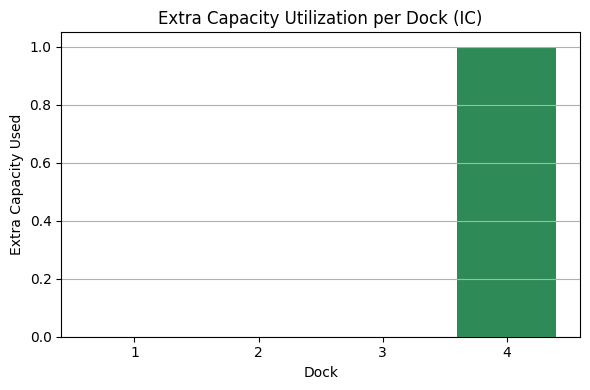

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(df_IC['Dock'].astype(str), df_IC['Extra_Capacity_Used'], color='seagreen')
ax.set_xlabel("Dock")
ax.set_ylabel("Extra Capacity Used")
ax.set_title("Extra Capacity Utilization per Dock (IC)")
plt.tight_layout()
plt.grid(axis='y')
plt.show()

In [17]:
original_obj = value(model.obj)

<h1> If Dock 3 Constraint is Relaxed

In [18]:
model.del_component(model.c2)
def number_ships_to_pier(model, j):
  if j==3:
    return pyo.Constraint.Skip
  else:
    return pyo.quicksum(model.X[i,j] for i in model.i) <=2
model.c2 = pyo.Constraint(model.j, rule= number_ships_to_pier)

In [19]:
solver= pyo.SolverFactory('glpk')
result = solver.solve(model, tee=False)  # set tee=True to see the full solver log
result.write()

In [20]:
new_obj = value(model.obj)
print(f"Original Objective: {original_obj}, New Objective: {new_obj}")

Original Objective: 1803.2706014701052, New Objective: 1605.5574635658484


In [21]:
if result.solver.termination_condition != TerminationCondition.infeasible:
    for i, j in model.X.index_set():
        if model.X[i, j].value > 0:
            print(f"X[{i}, {j}] = {model.X[i,j].value}")
    for i in model.W.index_set():
        if model.W[i].value >= 0:
            print(f"W[{i}] = {model.W[i].value}")
    for i in model.s.index_set():
        if model.s[i].value >= 0:
            print(f"s[{i}] = {model.s[i].value}")
            
    for i,q, j in model.y.index_set():
        if model.y[i,q,j].value == 1:
            print(f"y[{i},{q}, {j}] = {model.y[i,q,j].value}")
            
    for i,j in model.u.index_set():
        if model.u[i,j].value > 0:
            print(f"u[{i},{j}] = {model.u[i,j].value}")
            
    
    obj_val = value(model.obj)
    print(f"Objective value: {obj_val}")

X[1, 2] = 1.0
X[2, 4] = 1.0
X[3, 3] = 1.0
X[4, 1] = 1.0
X[5, 1] = 1.0
X[6, 2] = 1.0
X[7, 3] = 1.0
X[8, 4] = 1.0
W[1] = 0.0
W[2] = 0.0
W[3] = 19.2670572909898
W[4] = 0.0
W[5] = 20.457012660854
W[6] = 20.6958212309185
W[7] = 0.0
W[8] = 8.24083515240811
s[1] = 4.76552698703798
s[2] = 1.00459250301696
s[3] = 22.9200559414305
s[4] = 6.05417812493725
s[5] = 22.3262021407276
s[6] = 22.813811450173
s[7] = 4.62295182452406
s[8] = 14.8420135358433
y[1,6, 2] = 1.0
y[2,8, 4] = 1.0
y[4,5, 1] = 1.0
y[7,3, 3] = 1.0
u[3,1] = 10.0
u[3,2] = 9.26705729098979
u[5,1] = 10.0
u[5,2] = 10.457012660854
u[6,1] = 10.0
u[6,2] = 10.6958212309185
u[8,1] = 8.24083515240811
Objective value: 1605.5574635658484


In [22]:
if result.solver.termination_condition != TerminationCondition.infeasible:
    # Export X[i, j]
    X_data = [(i, j, model.X[i, j].value) for (i, j) in model.X if model.X[i, j].value is not None and model.X[i, j].value > 0]
    df_X = pd.DataFrame(X_data, columns=['Ship', 'Dock', 'Assigned'])

    # Export W[i]
    W_data = [(i, model.W[i].value) for i in model.W if model.W[i].value is not None]
    df_W = pd.DataFrame(W_data, columns=['Ship', 'Wait_Time'])

    # Export s[i]
    s_data = [(i, model.s[i].value) for i in model.s if model.s[i].value is not None]
    df_s = pd.DataFrame(s_data, columns=['Ship', 'Start_Time'])

    # Export y[i, q, j]
    y_data = [(i, q, j, model.y[i, q, j].value) for (i, q, j) in model.y if model.y[i, q, j].value == 1]
    df_y = pd.DataFrame(y_data, columns=['Ship1', 'Ship2', 'Dock', 'y_value'])

    # Export u[i, k]
    u_data = [(i, k, model.u[i, k].value) for (i, k) in model.u if model.u[i, k].value is not None and model.u[i, k].value > 0]
    df_u = pd.DataFrame(u_data, columns=['Ship', 'Objective_K', 'u_value'])

    # Export IC[j]
    IC_data = [(j, model.IC[j].value) for j in model.IC ]
    df_IC = pd.DataFrame(IC_data, columns=['Dock', 'Extra_Capacity_Used'])

    #Exort Un[i,j]

    # Objective value
    obj_val = value(model.obj)

    # Save all to Excel
    with pd.ExcelWriter("results/pyomo_results_dock3_loosened.xlsx") as writer:
        df_X.to_excel(writer, sheet_name="X", index=False)
        df_W.to_excel(writer, sheet_name="W", index=False)
        df_s.to_excel(writer, sheet_name="s", index=False)
        df_y.to_excel(writer, sheet_name="y", index=False)
        df_u.to_excel(writer, sheet_name="u", index=False)
        df_IC.to_excel(writer, sheet_name="IC", index=False)

    print("Objective Value:", obj_val)
    print("Results saved to results/pyomo_results_dock3_loosened.xlsx")

Objective Value: 1605.5574635658484
Results saved to pyomo_results_dock3_loosened.xlsx


In [23]:
df_Un = pd.DataFrame({'Ship': df_s['Ship'], 'Unload_Duration': 10})  # Replace 10 with actual Un[i,j]

priority_data = [(i, float(value(model.P[i]))) for i in model.P]
df_priority = pd.DataFrame(priority_data, columns=['Ship', 'Priority_Value'])

df_priority['Priority'] = df_priority['Priority_Value'].apply(classify_priority)
# Merge everything
df_schedule = df_X.merge(df_s, on="Ship").merge(df_Un, on="Ship").merge(df_priority, on="Ship")
df_schedule['End_Time'] = df_schedule['Start_Time'] + df_schedule['Unload_Duration']



df_schedule['Color'] = df_schedule['Priority'].map(priority_colors)

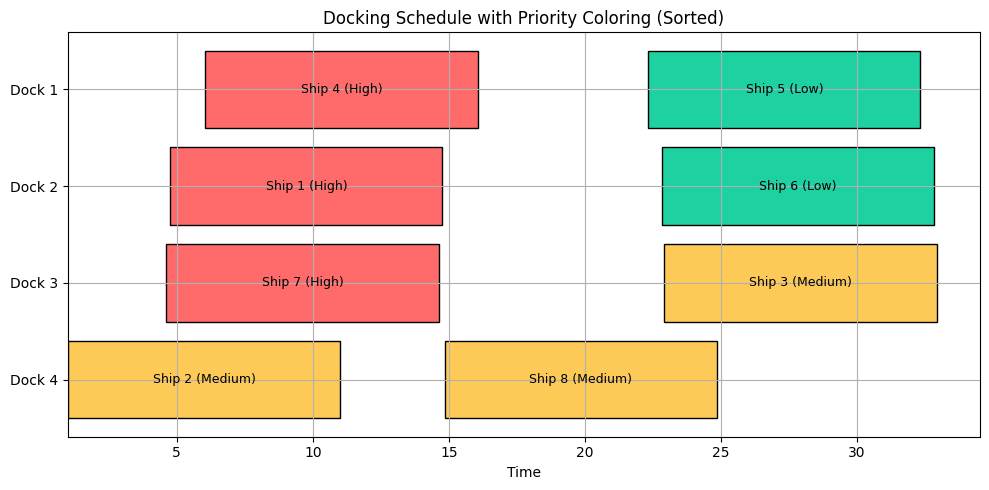

In [24]:
# Make sure dock is numeric if it isn't already
df_schedule['Dock'] = df_schedule['Dock'].astype(int)

# Sort by Dock (numerically)
df_schedule = df_schedule.sort_values(by='Dock', ascending=False)

# Create an ordered list of dock labels
dock_labels = sorted(df_schedule['Dock'].unique())
dock_labels = [f'Dock {d}' for d in dock_labels]

# === Gantt Chart with sorted docks ===
fig, ax = plt.subplots(figsize=(10, 5))
for _, row in df_schedule.iterrows():
    ax.barh(y=f'Dock {row.Dock}', left=row.Start_Time, width=row.Unload_Duration,
            color=row.Color, edgecolor='black')
    ax.text(row.Start_Time + row.Unload_Duration/2, f'Dock {row.Dock}',
            f'Ship {row.Ship} ({row.Priority})', va='center', ha='center', fontsize=9)

ax.set_yticks([f'Dock {d}' for d in sorted(df_schedule['Dock'].unique())])
ax.set_yticklabels(dock_labels)  # ensure consistent order
ax.set_xlabel("Time")
ax.set_title("Docking Schedule with Priority Coloring (Sorted)")
plt.grid(True)
plt.tight_layout()
plt.show()

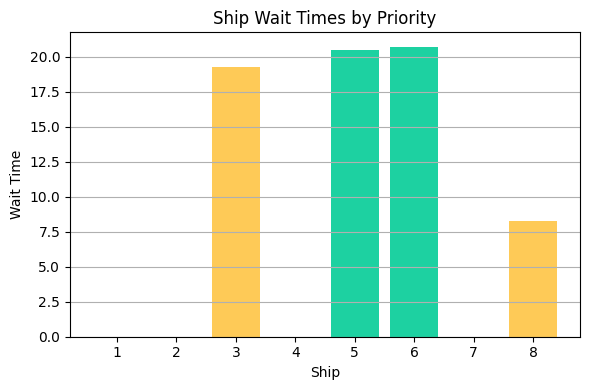

In [25]:
df_W = df_W.merge(df_priority, on="Ship")
fig, ax = plt.subplots(figsize=(6, 4))
colors = df_W['Priority'].map(priority_colors)
ax.bar(df_W['Ship'].astype(str), df_W['Wait_Time'], color=colors)
ax.set_xlabel("Ship")
ax.set_ylabel("Wait Time")
ax.set_title("Ship Wait Times by Priority")
plt.tight_layout()
plt.grid(axis='y')
plt.show()


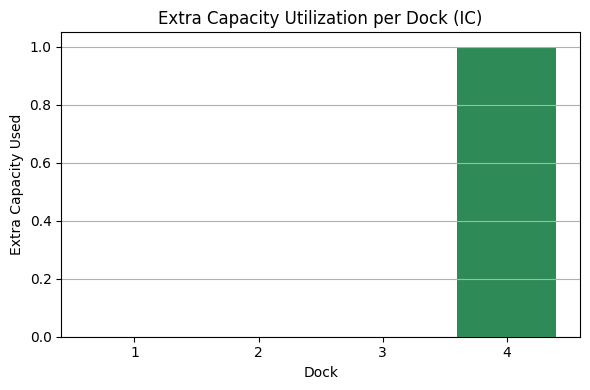

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(df_IC['Dock'].astype(str), df_IC['Extra_Capacity_Used'], color='seagreen')
ax.set_xlabel("Dock")
ax.set_ylabel("Extra Capacity Used")
ax.set_title("Extra Capacity Utilization per Dock (IC)")
plt.tight_layout()
plt.grid(axis='y')
plt.show()

In [27]:
model.del_component(model.c2)
def number_ships_to_pier(model, j):
  if j==3:
    return pyo.quicksum(model.X[i,j] for i in model.i) ==3
  else:
    return pyo.quicksum(model.X[i,j] for i in model.i) <=2
model.c2 = pyo.Constraint(model.j, rule= number_ships_to_pier)

<h1> Sensitivity Analysis

In [28]:
original_o2_value = pyo.value(model.O[2])
original_Un_7_3_value = pyo.value(model.Un[7, 3])
original_C_2_value = pyo.value(model.C[2])
original_C_3_value = pyo.value(model.C[3])
original_a_6_value = pyo.value(model.a[6])

<h2> Part A: Sensitivity Analysis on O[2]

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from pyomo.environ import value

  # Store the original value of O[2]
# Step range: 5 to 10 with 0.5 increments
o2_values = [round(v * 0.5, 2) for v in range(10, 21)]  # Gives values from 5.0 to 10.0 in 0.5 steps
results = []
o2_values.insert(0, original_o2_value)  # Append the original value to the list
# Loop through each value for O[2]
for val in o2_values :
    model.O[2] = val  # Update the parameter

    # Solve the model
    solver = pyo.SolverFactory('glpk')
    result = solver.solve(model)

    # Record objective
    obj_val = value(model.obj)

    # Record decision variable x[i,j]
    x_vals = {(i, j): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i, j].value >0}
    x_vals = {(f'x[{i},{j}]'): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i,j].value>0}
    W_vals = {(f'W[{i}]'): value(model.W[i]) for i in model.i}
    IC_vals = {(f'IC[{j}]'): value(model.IC[j]) for j in model.j}
    s_vals = {(f's[{i}]'): value(model.s[i]) for i in model.i}
    Un_vals = {(f'Un[{i},{j}]'): value(model.Un[i,j]) for i in model.i for j in model.j}

    # Flatten results into one row per (o2_val)
    row = {
        'o2_value': val,
        'objective': obj_val,
        'x_values': x_vals,
        'W_vals': W_vals,
        'IC_vals': IC_vals,
        's_vals': s_vals,
        'Un_vals': Un_vals
    }
    results.append(row)

# Convert to DataFrame
df_results = pd.DataFrame(results)

# Expand x_values into columns
df_x = df_results['x_values'].apply(pd.Series)
df_W = df_results['W_vals'].apply(pd.Series)
df_IC = df_results['IC_vals'].apply(pd.Series)
df_s = df_results['s_vals'].apply(pd.Series)
df_Un = df_results['Un_vals'].apply(pd.Series)
df_final = pd.concat([df_results[['o2_value', 'objective']], df_x,df_W,df_IC], axis=1)
df_final

,o2_value,objective,"x[1,2]","x[2,4]","x[3,3]","x[4,1]","x[5,3]","x[6,2]","x[7,3]","x[8,4]",...,W[3],W[4],W[5],W[6],W[7],W[8],IC[1],IC[2],IC[3],IC[4]
0,9.727825,1803.270601,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,20.695821,0.0,8.240835,0.0,0.0,0.0,1.0
1,5.000000,1755.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,15.967996,0.0,8.240835,0.0,0.0,0.0,1.0
2,5.500000,1760.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,16.467996,0.0,8.240835,0.0,0.0,0.0,1.0
3,6.000000,1765.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,16.967996,0.0,8.240835,0.0,0.0,0.0,1.0
4,6.500000,1770.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,17.467996,0.0,8.240835,0.0,0.0,0.0,1.0
5,7.000000,1775.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,17.967996,0.0,8.240835,0.0,0.0,0.0,1.0
6,7.500000,1780.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,18.467996,0.0,8.240835,0.0,0.0,0.0,1.0
7,8.000000,1785.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,18.967996,0.0,8.240835,0.0,0.0,0.0,1.0
8,8.500000,1790.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,19.467996,0.0,8.240835,0.0,0.0,0.0,1.0
9,9.000000,1795.992348,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,19.967996,0.0,8.240835,0.0,0.0,0.0,1.0


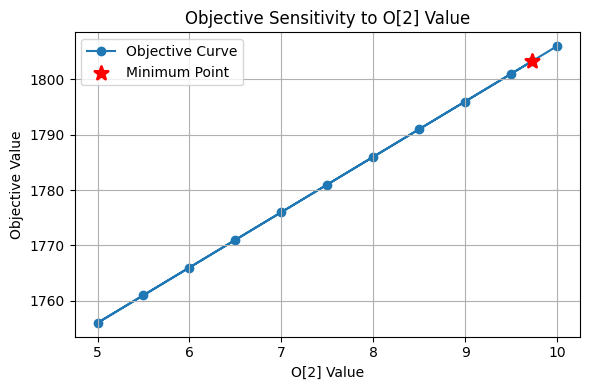

In [30]:
plt.figure(figsize=(6, 4))

# Line plot with label
plt.plot(df_final['o2_value'], df_final['objective'], marker='o', label='Objective Curve', zorder=1)


plt.scatter(
    x=df_final['o2_value'].iloc[0], y=df_final['objective'].iloc[0],
    color='red', s=100, linewidths=2,marker='*',
    label='Minimum Point', zorder=3
)

plt.xlabel('O[2] Value')
plt.ylabel('Objective Value')
plt.title('Objective Sensitivity to O[2] Value')
plt.grid(True, zorder=0)
plt.legend()
plt.tight_layout()
plt.show()


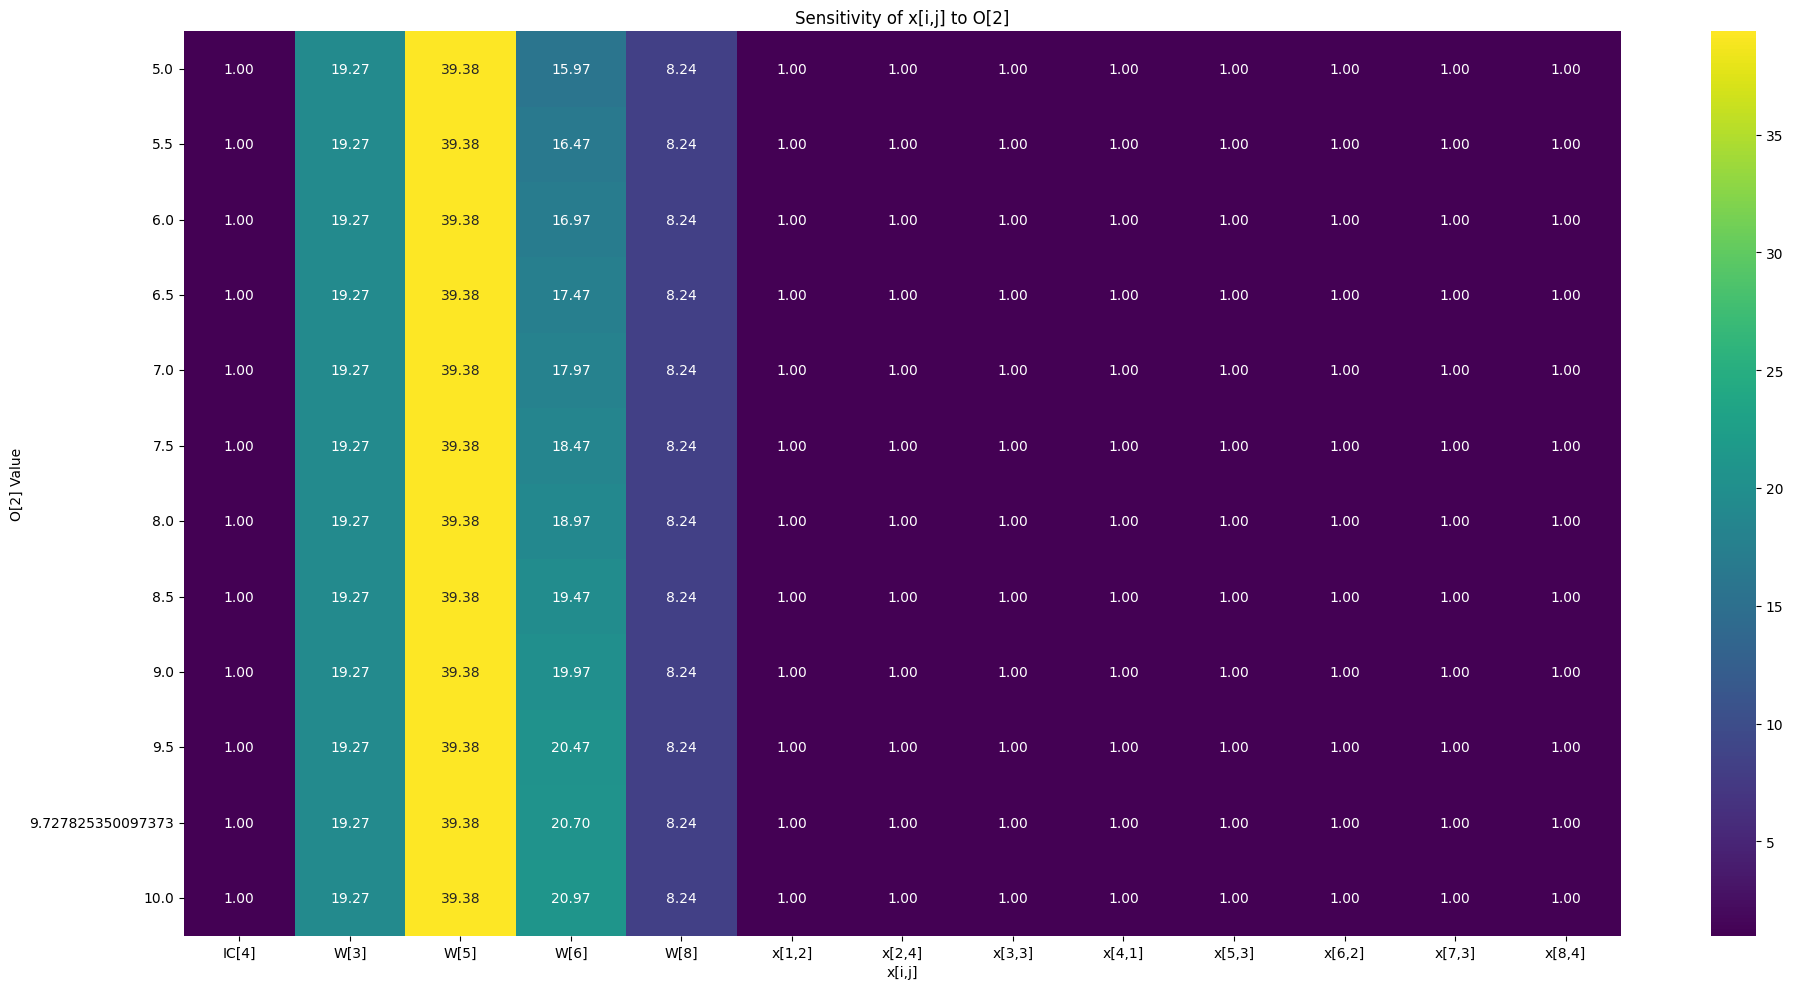

In [31]:
# Convert wide-form df to long-form
df_long = df_final.melt(id_vars=['o2_value', 'objective'], var_name='(i,j)', value_name='x_val')

# Filter only x variables that changed meaningfully (optional)
df_long = df_long[df_long['x_val'].abs() > 1e-3]

# Heatmap of decision variable changes
pivot = df_long.pivot(index='o2_value', columns='(i,j)', values='x_val')
plt.figure(figsize=(20, 10))
sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f")
plt.title("Sensitivity of x[i,j] to O[2]")
plt.xlabel("x[i,j]")
plt.ylabel("O[2] Value")
plt.tight_layout()
plt.show()


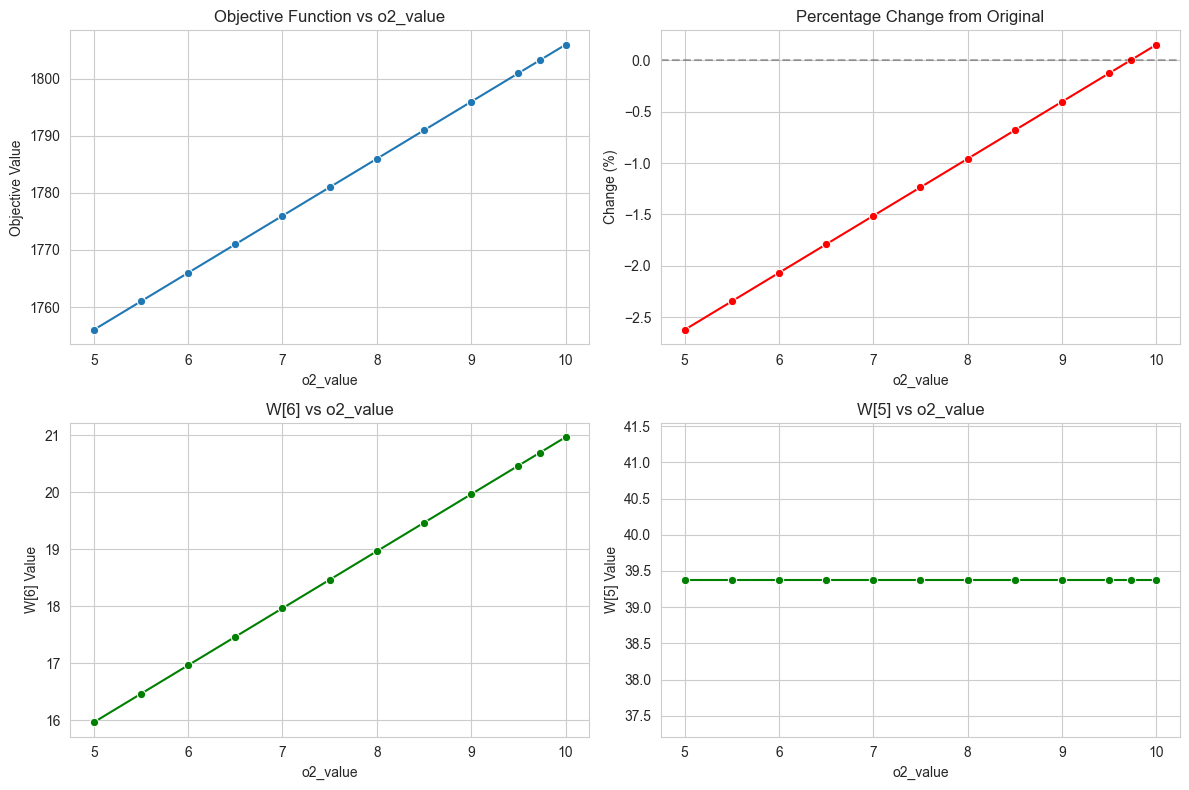


Sensitivity Analysis Summary:
    Variable  Original Value    Min Value    Max Value  Range  Sensitivity
0  objective     1803.270601  1755.992348  1805.992348   50.0     2.772740
1       W[6]       20.695821    15.967996    20.967996    5.0    24.159467
2       W[5]       39.378891    39.378891    39.378891    0.0     0.000000


In [32]:
# Set the style for better visualizations
sns.set_style("whitegrid")
plt.figure(figsize=(12, 8))

# 1. Plot the objective function vs o2_value
plt.subplot(2, 2, 1)
sns.lineplot(data=df_final, x='o2_value', y='objective', marker='o')
plt.title('Objective Function vs o2_value')
plt.xlabel('o2_value')
plt.ylabel('Objective Value')

# 2. Calculate and plot percentage changes from original
original_obj = df_final['objective'].iloc[0]
df_final['pct_change'] = ((df_final['objective'] - original_obj) / original_obj) * 100

plt.subplot(2, 2, 2)
sns.lineplot(data=df_final, x='o2_value', y='pct_change', marker='o', color='red')
plt.axhline(0, color='black', linestyle='--', alpha=0.3)
plt.title('Percentage Change from Original')
plt.xlabel('o2_value')
plt.ylabel('Change (%)')

# 3. Highlight key variables that change (you'll need to add your actual variables)
# For example, if W[6] changes:
if 'W[6]' in df_final.columns:
    plt.subplot(2, 2, 3)
    sns.lineplot(data=df_final, x='o2_value', y='W[6]', marker='o', color='green')
    plt.title('W[6] vs o2_value')
    plt.xlabel('o2_value')
    plt.ylabel('W[6] Value')

if 'W[5]' in df_final.columns:
    plt.subplot(2, 2, 4)
    sns.lineplot(data=df_final, x='o2_value', y='W[5]', marker='o', color='green')
    plt.title('W[5] vs o2_value')
    plt.xlabel('o2_value')
    plt.ylabel('W[5] Value')

# Adjust spacing and show the plot
plt.tight_layout()
plt.show()

# Additional analysis: Create a table showing the differences
if len(df_final) > 1:
    comparison_df = pd.DataFrame({
        'Variable': ['objective', 'W[6]', 'W[5]'],  # Add other variables you're interested in
        'Original Value': [df_final['objective'].iloc[0], df_final['W[6]'].iloc[0], df_final['W[5]'].iloc[0]],
        'Min Value': [df_final['objective'].min(), df_final['W[6]'].min(), df_final['W[5]'].min()],
        'Max Value': [df_final['objective'].max(), df_final['W[6]'].max(), df_final['W[5]'].max()],
        'Range': [df_final['objective'].max() - df_final['objective'].min(), 
                 df_final['W[6]'].max() - df_final['W[6]'].min(), 
                 df_final['W[5]'].max() - df_final['W[5]'].min()],
        'Sensitivity': [abs(((df_final['objective'].max() - df_final['objective'].min()) / df_final['objective'].iloc[0]) * 100),
                        abs(((df_final['W[6]'].max() - df_final['W[6]'].min()) / df_final['W[6]'].iloc[0]) * 100), 
                        abs(((df_final['W[5]'].max() - df_final['W[5]'].min()) / df_final['W[5]'].iloc[0]) * 100)]
    })
    print("\nSensitivity Analysis Summary:")
    print(comparison_df)


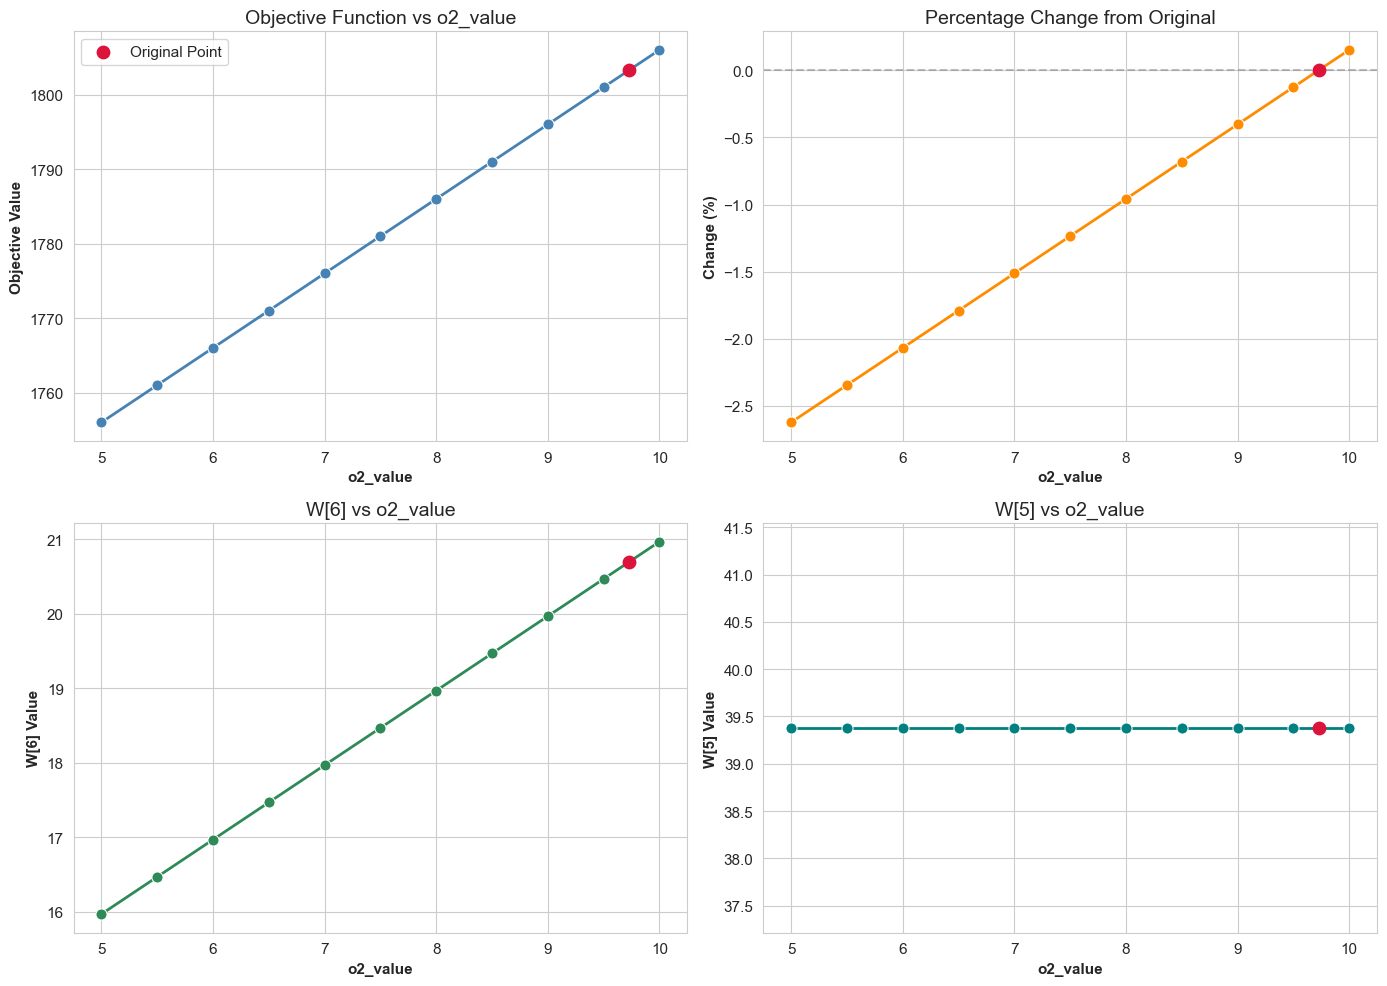

In [33]:
# Set Seaborn style
sns.set_style("whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelweight': 'bold', 'axes.titlesize': 14})

# Define colors and marker styles
main_color = 'steelblue'
highlight_color = 'crimson'
marker_style = 'o'
marker_size = 8
highlight_size = 80

# Start plot
plt.figure(figsize=(14, 10))

# Original values
orig_idx = 0
orig_x = df_final['o2_value'].iloc[orig_idx]
orig_obj = df_final['objective'].iloc[orig_idx]

# 1. Objective vs o2_value
plt.subplot(2, 2, 1)
sns.lineplot(data=df_final, x='o2_value', y='objective', marker=marker_style,
             color=main_color, markersize=marker_size, linewidth=2)
plt.scatter(orig_x, orig_obj, color=highlight_color, s=highlight_size, label='Original Point', zorder=5)
plt.title('Objective Function vs o2_value')
plt.xlabel('o2_value')
plt.ylabel('Objective Value')
plt.legend()

# 2. Percentage change from original
df_final['pct_change'] = ((df_final['objective'] - orig_obj) / orig_obj) * 100

plt.subplot(2, 2, 2)
sns.lineplot(data=df_final, x='o2_value', y='pct_change', marker=marker_style,
             color='darkorange', markersize=marker_size, linewidth=2)
plt.scatter(orig_x, df_final['pct_change'].iloc[orig_idx], color=highlight_color, s=highlight_size, zorder=5)
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.title('Percentage Change from Original')
plt.xlabel('o2_value')
plt.ylabel('Change (%)')

# 3. W[6] vs o2_value (if exists)
if 'W[6]' in df_final.columns:
    plt.subplot(2, 2, 3)
    sns.lineplot(data=df_final, x='o2_value', y='W[6]', marker=marker_style,
                 color='seagreen', markersize=marker_size, linewidth=2)
    plt.scatter(orig_x, df_final['W[6]'].iloc[orig_idx], color=highlight_color, s=highlight_size, zorder=5)
    plt.title('W[6] vs o2_value')
    plt.xlabel('o2_value')
    plt.ylabel('W[6] Value')

# 4. W[5] vs o2_value (if exists)
if 'W[5]' in df_final.columns:
    plt.subplot(2, 2, 4)
    sns.lineplot(data=df_final, x='o2_value', y='W[5]', marker=marker_style,
                 color='teal', markersize=marker_size, linewidth=2)
    plt.scatter(orig_x, df_final['W[5]'].iloc[orig_idx], color=highlight_color, s=highlight_size, zorder=5)
    plt.title('W[5] vs o2_value')
    plt.xlabel('o2_value')
    plt.ylabel('W[5] Value')

plt.tight_layout()
plt.show()

In [34]:
if len(df_final) > 1:
    comparison_df = pd.DataFrame({
        'Variable': ['objective', 'W[6]', 'W[5]'],
        'Original Value': [df_final['objective'].iloc[0], df_final['W[6]'].iloc[0], df_final['W[5]'].iloc[0]],
        'Min Value': [df_final['objective'].min(), df_final['W[6]'].min(), df_final['W[5]'].min()],
        'Max Value': [df_final['objective'].max(), df_final['W[6]'].max(), df_final['W[5]'].max()],
        'Range': [df_final['objective'].max() - df_final['objective'].min(), 
                  df_final['W[6]'].max() - df_final['W[6]'].min(), 
                  df_final['W[5]'].max() - df_final['W[5]'].min()],
        'Sensitivity (%)': [
            abs((df_final['objective'].max() - df_final['objective'].min()) / df_final['objective'].iloc[0]) * 100,
            abs((df_final['W[6]'].max() - df_final['W[6]'].min()) / df_final['W[6]'].iloc[0]) * 100,
            abs((df_final['W[5]'].max() - df_final['W[5]'].min()) / df_final['W[5]'].iloc[0]) * 100
        ]
    })

    styled_df = comparison_df.style \
        .set_properties(**{'font-weight': 'bold'}, subset=['Variable']) \
        .background_gradient(cmap='YlGnBu', subset=['Sensitivity (%)']) \
        .format({
            'Original Value': '{:.4f}',
            'Min Value': '{:.4f}',
            'Max Value': '{:.4f}',
            'Range': '{:.4f}',
            'Sensitivity (%)': '{:.2f}%'
        })

    print("\nSensitivity Analysis Summary:")
    display(styled_df)



Sensitivity Analysis Summary:


,Variable,Original Value,Min Value,Max Value,Range,Sensitivity (%)
0,objective,1803.2706,1755.9923,1805.9923,50.0000,2.77%
1,W[6],20.6958,15.9680,20.9680,5.0000,24.16%
2,W[5],39.3789,39.3789,39.3789,0.0000,0.00%


<h2> Part B: Sensitivity Analysis on Un[7,3]

In [35]:
model.O[2] = original_o2_value  # Reset to original value

In [36]:
Un_7_3_values = [round(v * 0.5, 2) for v in range(10, 31)]  # Gives values from 5.0 to 10.0 in 0.5 steps
results = []
Un_7_3_values.insert(0, original_Un_7_3_value)  # Append the original value to the list
# Loop through each value for o[3]
for val in Un_7_3_values :
    model.Un[7,3] = val  # Update the parameter

    # Solve the model
    solver = pyo.SolverFactory('glpk')
    result = solver.solve(model)

    # Record objective
    obj_val = value(model.obj)

    # Record decision variable x[i,j]
    x_vals = {(i, j): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i, j].value >0}
    x_vals = {(f'x[{i},{j}]'): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i,j].value>0}
    W_vals = {(f'W[{i}]'): value(model.W[i]) for i in model.i}
    IC_vals = {(f'IC[{j}]'): value(model.IC[j]) for j in model.j}
    s_vals = {(f's[{i}]'): value(model.s[i]) for i in model.i}
    Un_vals = {(f'Un[{i},{j}]'): value(model.Un[i,j]) for i in model.i for j in model.j}

    # Flatten results into one row per (o3_val)
    row = {
        'Un_7_3_value': val,
        'objective': obj_val,
        'x_values': x_vals,
        'W_vals': W_vals,
        'IC_vals': IC_vals,
        's_vals': s_vals,
        'Un_vals': Un_vals
    }
    results.append(row)

# Convert to DataFrame
df_results = pd.DataFrame(results)

# Expand x_values into columns
df_x = df_results['x_values'].apply(pd.Series)
df_W = df_results['W_vals'].apply(pd.Series)
df_IC = df_results['IC_vals'].apply(pd.Series)
df_s = df_results['s_vals'].apply(pd.Series)
df_Un = df_results['Un_vals'].apply(pd.Series)
df_final = pd.concat([df_results[['Un_7_3_value', 'objective']], df_x,df_W], axis=1)
df_final

,Un_7_3_value,objective,"x[1,2]","x[2,4]","x[3,3]","x[4,1]","x[5,3]","x[6,2]","x[7,3]","x[8,4]","x[1,3]","x[7,2]",W[1],W[2],W[3],W[4],W[5],W[6],W[7],W[8]
0,8.732291,1803.270601,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,19.267057,0.0,39.378891,20.695821,0.0,8.240835
1,5.000000,1709.963321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,15.534766,0.0,35.646600,20.695821,0.0,8.240835
2,5.500000,1722.463321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,16.034766,0.0,36.146600,20.695821,0.0,8.240835
3,6.000000,1734.963321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,16.534766,0.0,36.646600,20.695821,0.0,8.240835
4,6.500000,1747.463321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,17.034766,0.0,37.146600,20.695821,0.0,8.240835
5,7.000000,1759.963321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,17.534766,0.0,37.646600,20.695821,0.0,8.240835
6,7.500000,1772.463321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,18.034766,0.0,38.146600,20.695821,0.0,8.240835
7,8.000000,1784.963321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,18.534766,0.0,38.646600,20.695821,0.0,8.240835
8,8.500000,1797.463321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,19.034766,0.0,39.146600,20.695821,0.0,8.240835
9,9.000000,1809.963321,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,0.0,0.0,19.534766,0.0,39.646600,20.695821,0.0,8.240835


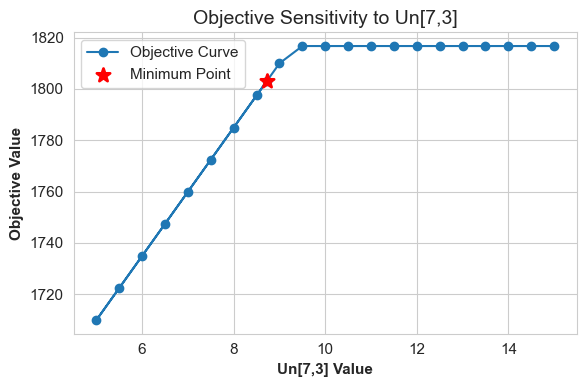

In [37]:
plt.figure(figsize=(6, 4))

# Line plot with label
plt.plot(df_final['Un_7_3_value'], df_final['objective'], marker='o', label='Objective Curve', zorder=1)


plt.scatter(
    x=df_final['Un_7_3_value'].iloc[0], y=df_final['objective'].iloc[0],
    color='red', s=100, linewidths=2,marker='*',
    label='Minimum Point', zorder=3
)

plt.xlabel('Un[7,3] Value')
plt.ylabel('Objective Value')
plt.title('Objective Sensitivity to Un[7,3]')
plt.grid(True, zorder=0)
plt.legend()
plt.tight_layout()
plt.show()


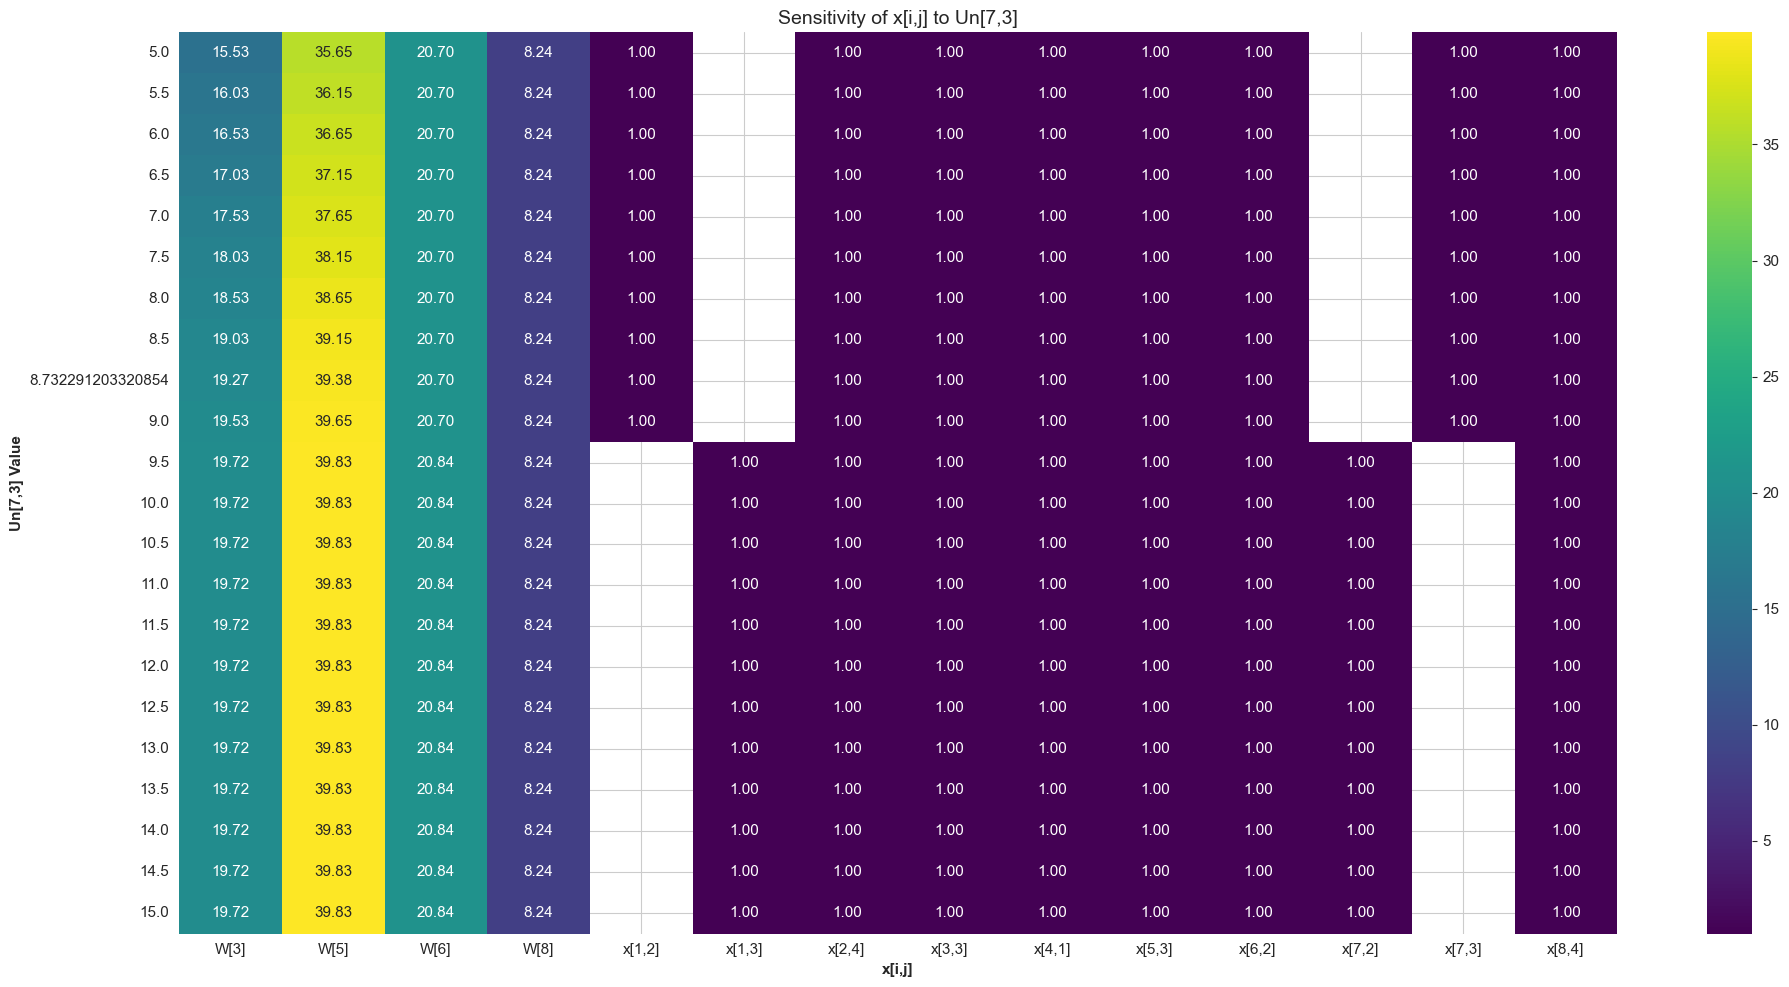

In [38]:
# Convert wide-form df to long-form
df_long = df_final.melt(id_vars=['Un_7_3_value', 'objective'], var_name='(i,j)', value_name='x_val')

# Filter only x variables that changed meaningfully (optional)
df_long = df_long[df_long['x_val'].abs() > 1e-3]

# Heatmap of decision variable changes
pivot = df_long.pivot(index='Un_7_3_value', columns='(i,j)', values='x_val')
plt.figure(figsize=(20, 10))
sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f")
plt.title("Sensitivity of x[i,j] to Un[7,3]")
plt.xlabel("x[i,j]")
plt.ylabel("Un[7,3] Value")
plt.tight_layout()
plt.show()

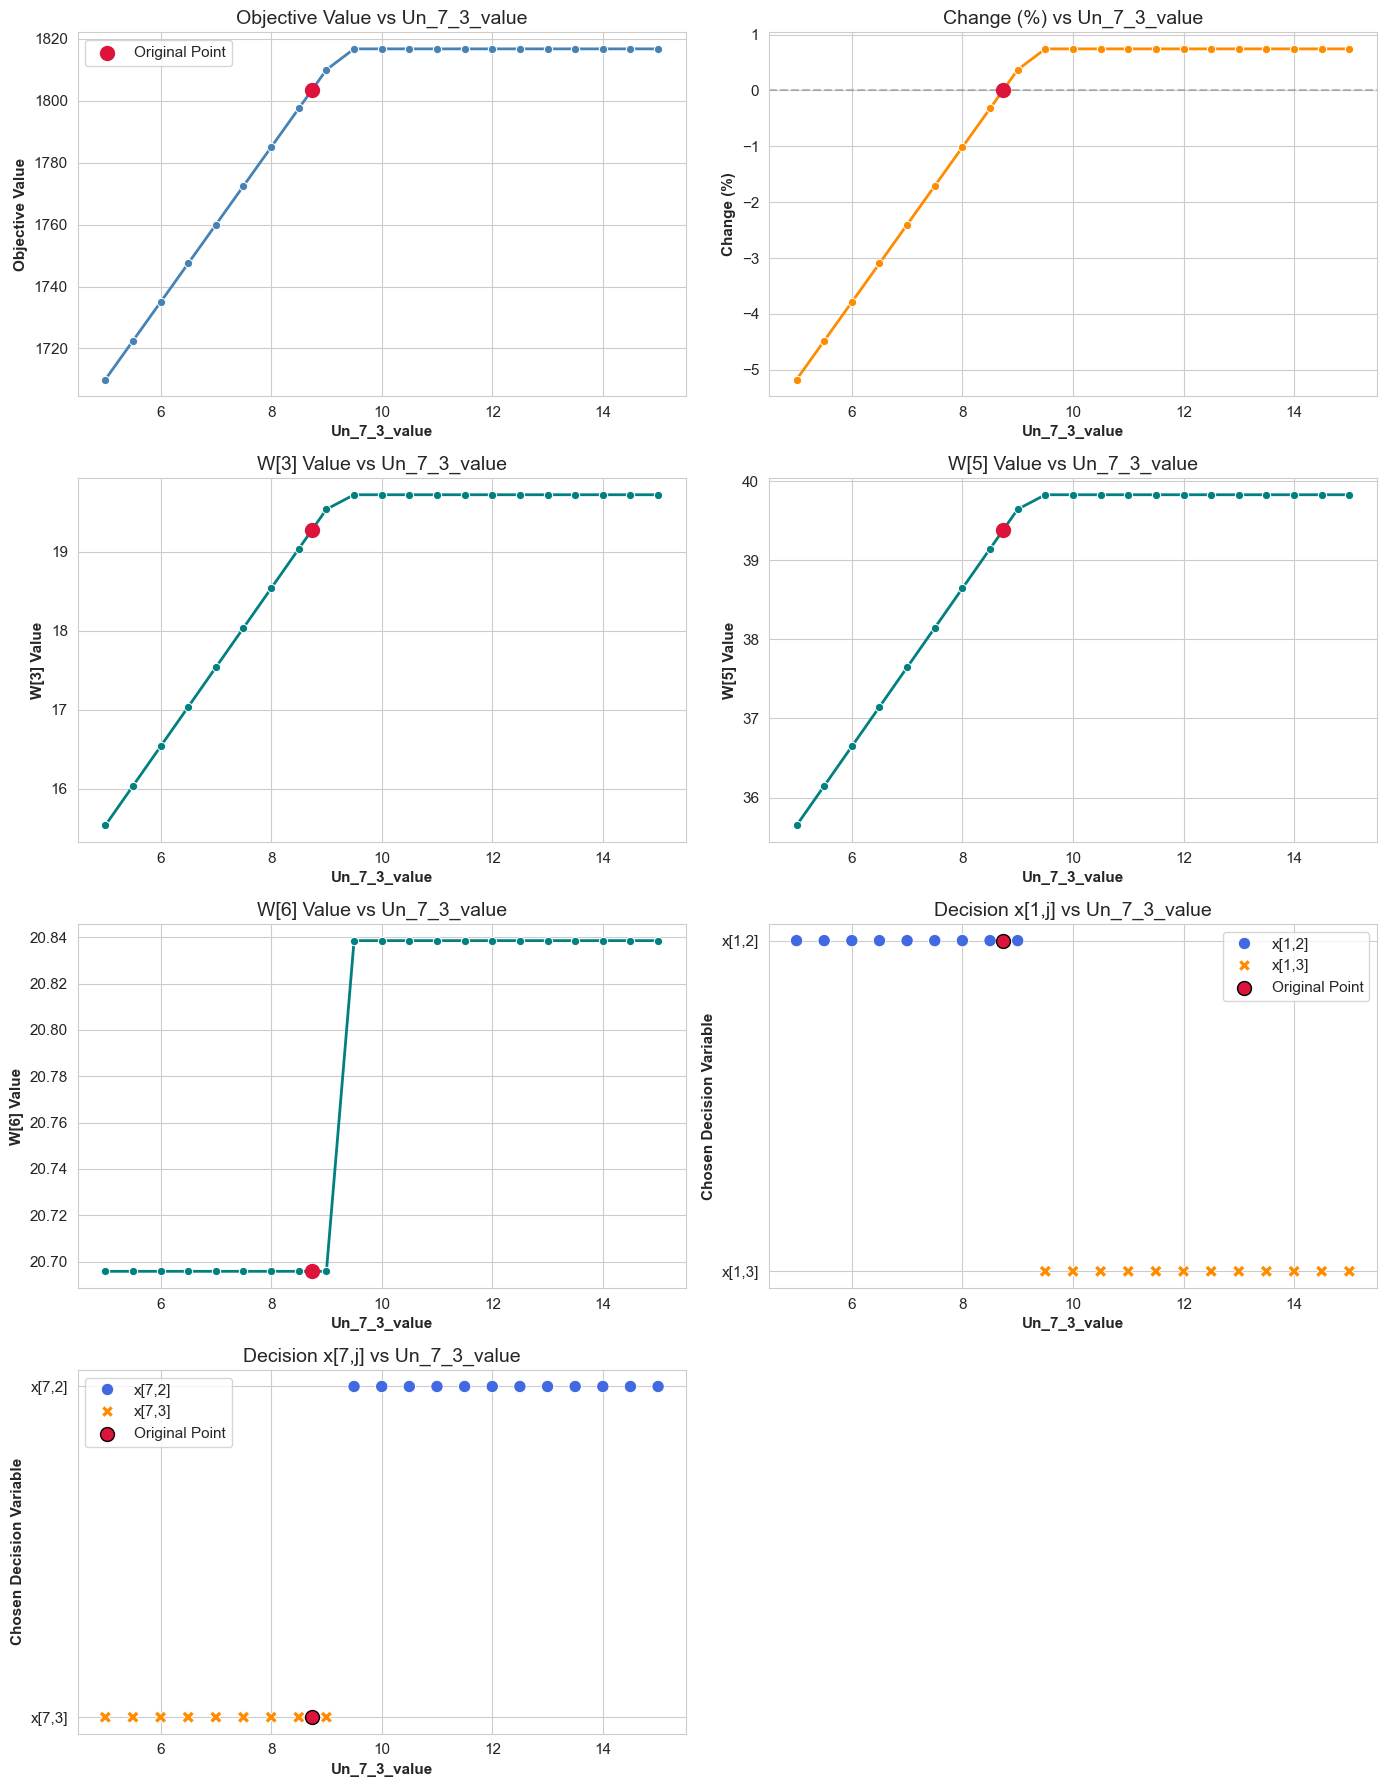

In [39]:
# Style settings
sns.set_style("whitegrid")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelweight': 'bold',
    'axes.titlesize': 14
})

# Colors & markers
main_color = 'steelblue'
highlight_color = 'crimson'
marker_style = 'o'
marker_size = 6
highlight_size = 100

# Original point index
orig_idx = 0
orig_x = df_final['Un_7_3_value'].iloc[orig_idx]
orig_obj = df_final['objective'].iloc[orig_idx]

# Calculate percentage change
df_final['pct_change'] = ((df_final['objective'] - orig_obj) / orig_obj) * 100

# List of variable plots (name, label)
variables = [
    ('objective', 'Objective Value'),
    ('pct_change', 'Change (%)'),
]

# Add W[i] columns if present
for w_col in ['W[3]', 'W[5]', 'W[6]']:
    if w_col in df_final.columns:
        variables.append((w_col, f'{w_col} Value'))

# Decision switches: add flags and labels
decision_plots = []

if {'x[1,2]', 'x[1,3]'}.issubset(df_final.columns):
    decision_plots.append(('x[1,2]', 'x[1,3]', 'Decision x[1,j]'))

if {'x[7,2]', 'x[7,3]'}.issubset(df_final.columns):
    decision_plots.append(('x[7,2]', 'x[7,3]', 'Decision x[7,j]'))

# Add decision switch placeholders to variable list
for _, _, label in decision_plots:
    variables.append((label, 'Chosen Decision'))

# Layout
num_plots = len(variables)
cols = 2
rows = math.ceil(num_plots / cols)

# Start plotting
plt.figure(figsize=(7 * cols, 4.5 * rows))

for i, (var, ylabel) in enumerate(variables, 1):
    plt.subplot(rows, cols, i)

    if var.startswith("Decision"):
        # Find correct pair of X variables
        for x1, x2, label in decision_plots:
            if label == var:
                break

        # Create long-form DataFrame
        df_x = df_final[['Un_7_3_value', x1, x2]].copy()
        df_x['Index'] = df_x.index
        df_long = df_x.melt(id_vars=['Un_7_3_value', 'Index'],
                            value_vars=[x1, x2],
                            var_name='Decision', value_name='Chosen')
        df_long = df_long[df_long['Chosen'] == 1]

        # Plot decision switch
        sns.scatterplot(data=df_long, x='Un_7_3_value', y='Decision', hue='Decision',
                        style='Decision', s=80,
                        palette={x1: 'royalblue', x2: 'darkorange'})

        # Highlight original point
        orig_dec = df_long[df_long['Index'] == orig_idx]
        plt.scatter(orig_dec['Un_7_3_value'], orig_dec['Decision'],
                    color=highlight_color, s=highlight_size,
                    edgecolor='black', label='Original Point', zorder=5)

        plt.title(f'{label} vs Un_7_3_value')
        plt.ylabel('Chosen Decision Variable')
        plt.xlabel('Un_7_3_value')
        plt.legend()

    else:
        # Standard continuous plot
        color = 'darkorange' if var == 'pct_change' else main_color
        if 'W[' in var:
            color = 'teal'

        sns.lineplot(data=df_final, x='Un_7_3_value', y=var,
                     marker=marker_style, color=color,
                     markersize=marker_size, linewidth=2)

        # Highlight original
        plt.scatter(orig_x, df_final[var].iloc[orig_idx],
                    color=highlight_color, s=highlight_size,
                    label='Original Point', zorder=5)

        if var == 'pct_change':
            plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

        plt.title(f'{ylabel} vs Un_7_3_value')
        plt.xlabel('Un_7_3_value')
        plt.ylabel(ylabel)

        if i == 1:
            plt.legend()

plt.tight_layout()
plt.show()


In [40]:
# Define target variables for sensitivity
target_vars = ['objective', 'W[3]', 'W[5]', 'W[6]', 'W[8]', 'IC[2]', 'IC[4]']
target_vars = [v for v in target_vars if v in df_final.columns]  # Filter only existing

if len(df_final) > 1 and target_vars:
    data = {
        'Variable': [],
        'Original Value': [],
        'Min Value': [],
        'Max Value': [],
        'Range': [],
        'Sensitivity (%)': []
    }

    for var in target_vars:
        original = df_final[var].iloc[0]
        min_val = df_final[var].min()
        max_val = df_final[var].max()
        range_val = max_val - min_val

        sensitivity = (abs(range_val) / original) * 100 if original != 0 else float('inf')

        data['Variable'].append(var)
        data['Original Value'].append(original)
        data['Min Value'].append(min_val)
        data['Max Value'].append(max_val)
        data['Range'].append(range_val)
        data['Sensitivity (%)'].append(sensitivity)

    comparison_df = pd.DataFrame(data)

    styled_df = comparison_df.style \
        .set_properties(**{'font-weight': 'bold'}, subset=['Variable']) \
        .background_gradient(cmap='YlOrRd', subset=['Sensitivity (%)']) \
        .format({
            'Original Value': '{:.4f}',
            'Min Value': '{:.4f}',
            'Max Value': '{:.4f}',
            'Range': '{:.4f}',
            'Sensitivity (%)': '{:.2f}%'
        })

    print("\n📊 Sensitivity Analysis Summary:")
    display(styled_df)



📊 Sensitivity Analysis Summary:


,Variable,Original Value,Min Value,Max Value,Range,Sensitivity (%)
0,objective,1803.2706,1709.9633,1816.7015,106.7381,5.92%
1,W[3],19.2671,15.5348,19.7187,4.1839,21.72%
2,W[5],39.3789,35.6466,39.8305,4.1839,10.62%
3,W[6],20.6958,20.6958,20.8385,0.1427,0.69%
4,W[8],8.2408,8.2408,8.2408,0.0000,0.00%


<h2> Part C: Sensitivity Analysis on C[2]

In [41]:
model.Un[7,3]=original_Un_7_3_value

In [42]:
C_2_values = [round(v * 1, 2) for v in range(5, 40)]  # Gives values from 5.0 to 80.0 in 0.5 steps
results = []
C_2_values.insert(0, original_C_2_value)  # Append the original value to the list
# Loop through each value for C[2]
for val in C_2_values :
    model.C[2] = val  # Update the parameter

    # Solve the model
    solver = pyo.SolverFactory('glpk')
    result = solver.solve(model)

    # Record objective
    obj_val = value(model.obj)

    # Record decision variable x[i,j]
    x_vals = {(i, j): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i, j].value >0}
    x_vals = {(f'x[{i},{j}]'): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i,j].value>0}
    W_vals = {(f'W[{i}]'): value(model.W[i]) for i in model.i}
    IC_vals = {(f'IC[{j}]'): value(model.IC[j]) for j in model.j}
    s_vals = {(f's[{i}]'): value(model.s[i]) for i in model.i}
    C_vals = {(f'C[{j}]'): value(model.C[j]) for j in model.j}

    # Flatten results into one row per (o3_val)
    row = {
        'C_2_value': val,
        'objective': obj_val,
        'x_values': x_vals,
        'W_vals': W_vals,
        'IC_vals': IC_vals,
        's_vals': s_vals,
        'C_vals': C_vals
    }
    results.append(row)

# Convert to DataFrame
df_results = pd.DataFrame(results)

# Expand x_values into columns
df_x = df_results['x_values'].apply(pd.Series)
df_W = df_results['W_vals'].apply(pd.Series)
df_IC = df_results['IC_vals'].apply(pd.Series)
df_s = df_results['s_vals'].apply(pd.Series)
df_C = df_results['C_vals'].apply(pd.Series)
df_final = pd.concat([df_results[['C_2_value', 'objective']], df_x,df_W,df_IC], axis=1)
df_final

,C_2_value,objective,"x[1,2]","x[2,4]","x[3,3]","x[4,1]","x[5,3]","x[6,2]","x[7,3]","x[8,4]",...,W[3],W[4],W[5],W[6],W[7],W[8],IC[1],IC[2],IC[3],IC[4]
0,40,1803.270601,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,20.695821,0.0,8.240835,0.0,0.0,0.0,1.0
1,5,1957.563252,1.0,1.0,1.0,1.0,1.0,NaN,1.0,NaN,...,19.267057,0.0,39.378891,12.724023,0.0,16.212633,0.0,14.0,0.0,7.0
2,6,1951.682805,1.0,1.0,1.0,1.0,1.0,NaN,1.0,NaN,...,19.267057,0.0,39.378891,12.724023,0.0,16.212633,0.0,13.0,0.0,7.0
3,7,1945.802357,1.0,1.0,1.0,1.0,1.0,NaN,1.0,NaN,...,19.267057,0.0,39.378891,12.724023,0.0,16.212633,0.0,12.0,0.0,7.0
4,8,1939.921910,1.0,1.0,1.0,1.0,1.0,NaN,1.0,NaN,...,19.267057,0.0,39.378891,12.724023,0.0,16.212633,0.0,11.0,0.0,7.0
5,9,1913.046946,NaN,1.0,1.0,NaN,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,22.577676,0.0,8.240835,0.0,15.0,0.0,1.0
6,10,1891.477309,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,20.695821,0.0,8.240835,0.0,15.0,0.0,1.0
7,11,1885.596862,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,20.695821,0.0,8.240835,0.0,14.0,0.0,1.0
8,12,1879.716415,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,20.695821,0.0,8.240835,0.0,13.0,0.0,1.0
9,13,1873.835968,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,19.267057,0.0,39.378891,20.695821,0.0,8.240835,0.0,12.0,0.0,1.0


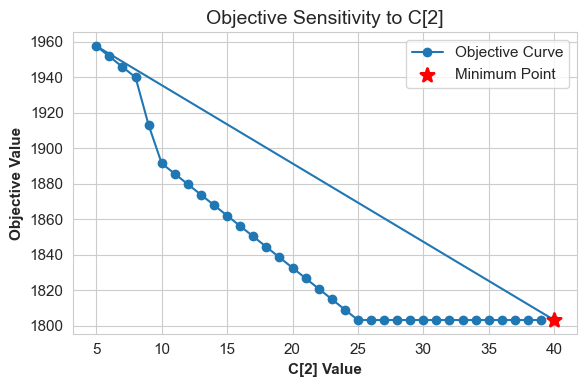

In [43]:
plt.figure(figsize=(6, 4))

# Line plot with label
plt.plot(df_final['C_2_value'], df_final['objective'], marker='o', label='Objective Curve', zorder=1)


plt.scatter(
    x=df_final['C_2_value'].iloc[0], y=df_final['objective'].iloc[0],
    color='red', s=100, linewidths=2,marker='*',
    label='Minimum Point', zorder=3
)

plt.xlabel('C[2] Value')
plt.ylabel('Objective Value')
plt.title('Objective Sensitivity to C[2]')
plt.grid(True, zorder=0)
plt.legend()
plt.tight_layout()
plt.show()

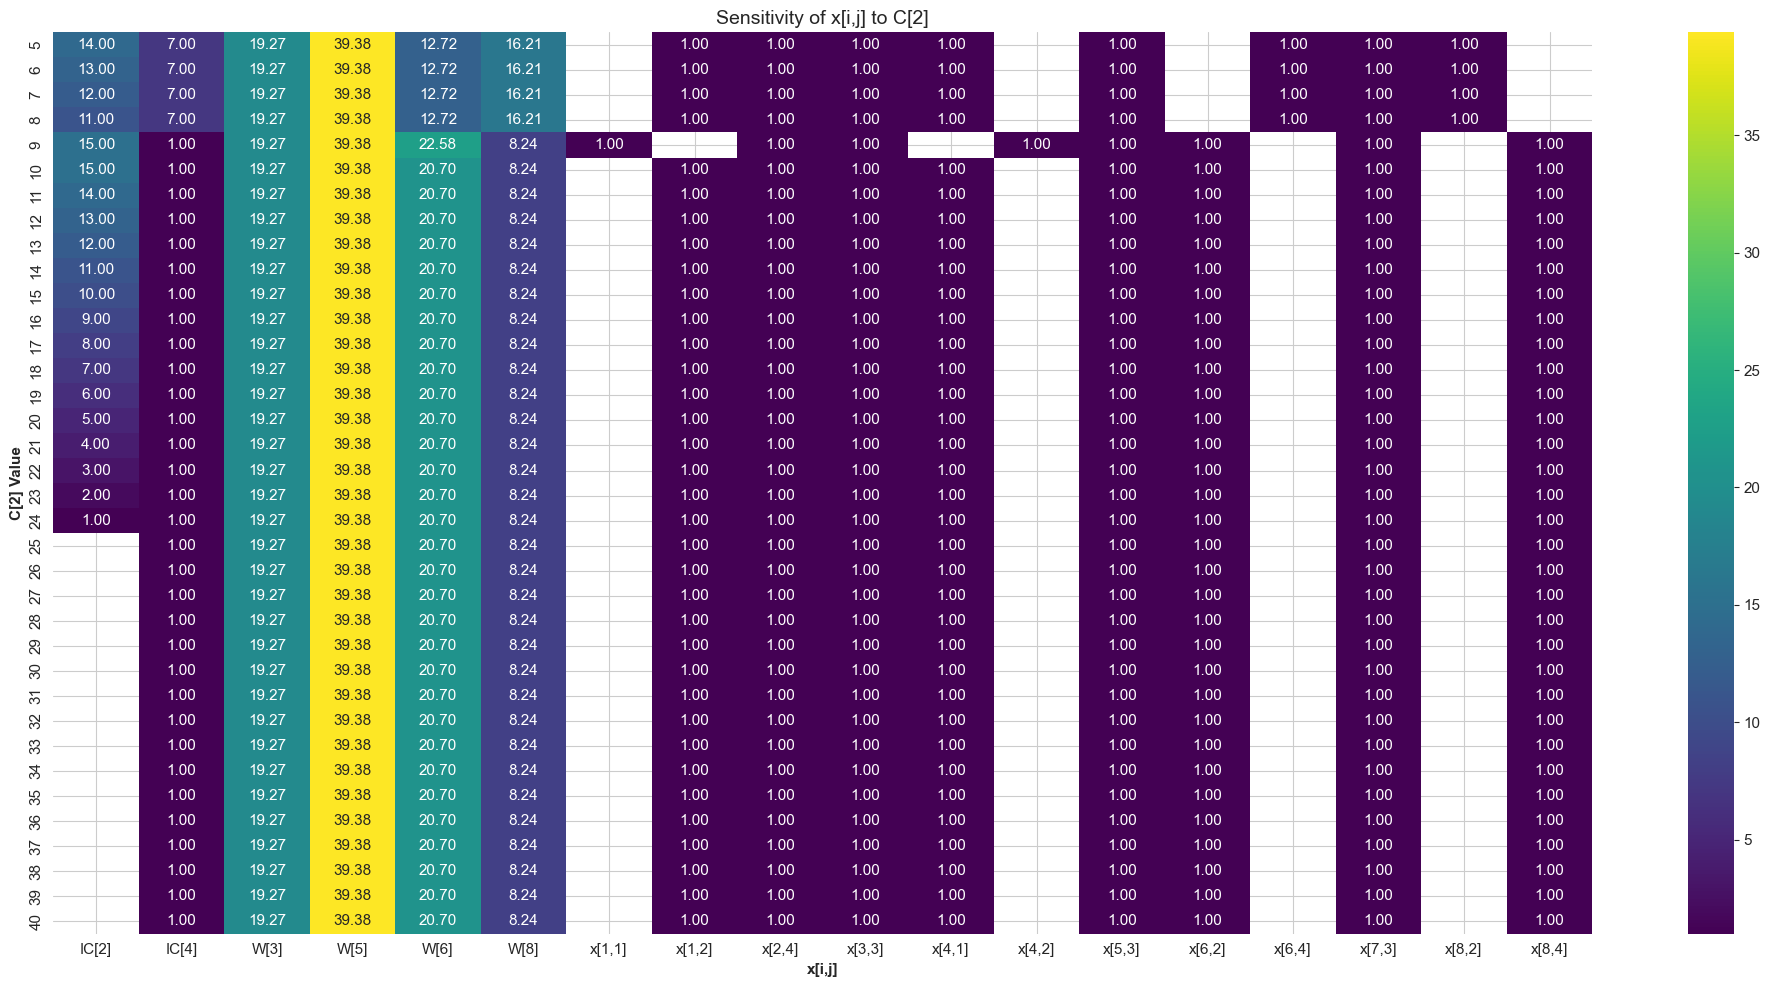

In [44]:
# Convert wide-form df to long-form
df_long = df_final.melt(id_vars=['C_2_value', 'objective'], var_name='(i,j)', value_name='x_val')

# Filter only x variables that changed meaningfully (optional)
df_long = df_long[df_long['x_val'].abs() > 1e-3]

# Heatmap of decision variable changes
pivot = df_long.pivot(index='C_2_value', columns='(i,j)', values='x_val')
plt.figure(figsize=(20, 10))
sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f")
plt.title("Sensitivity of x[i,j] to C[2]")
plt.xlabel("x[i,j]")
plt.ylabel("C[2] Value")
plt.tight_layout()
plt.show()

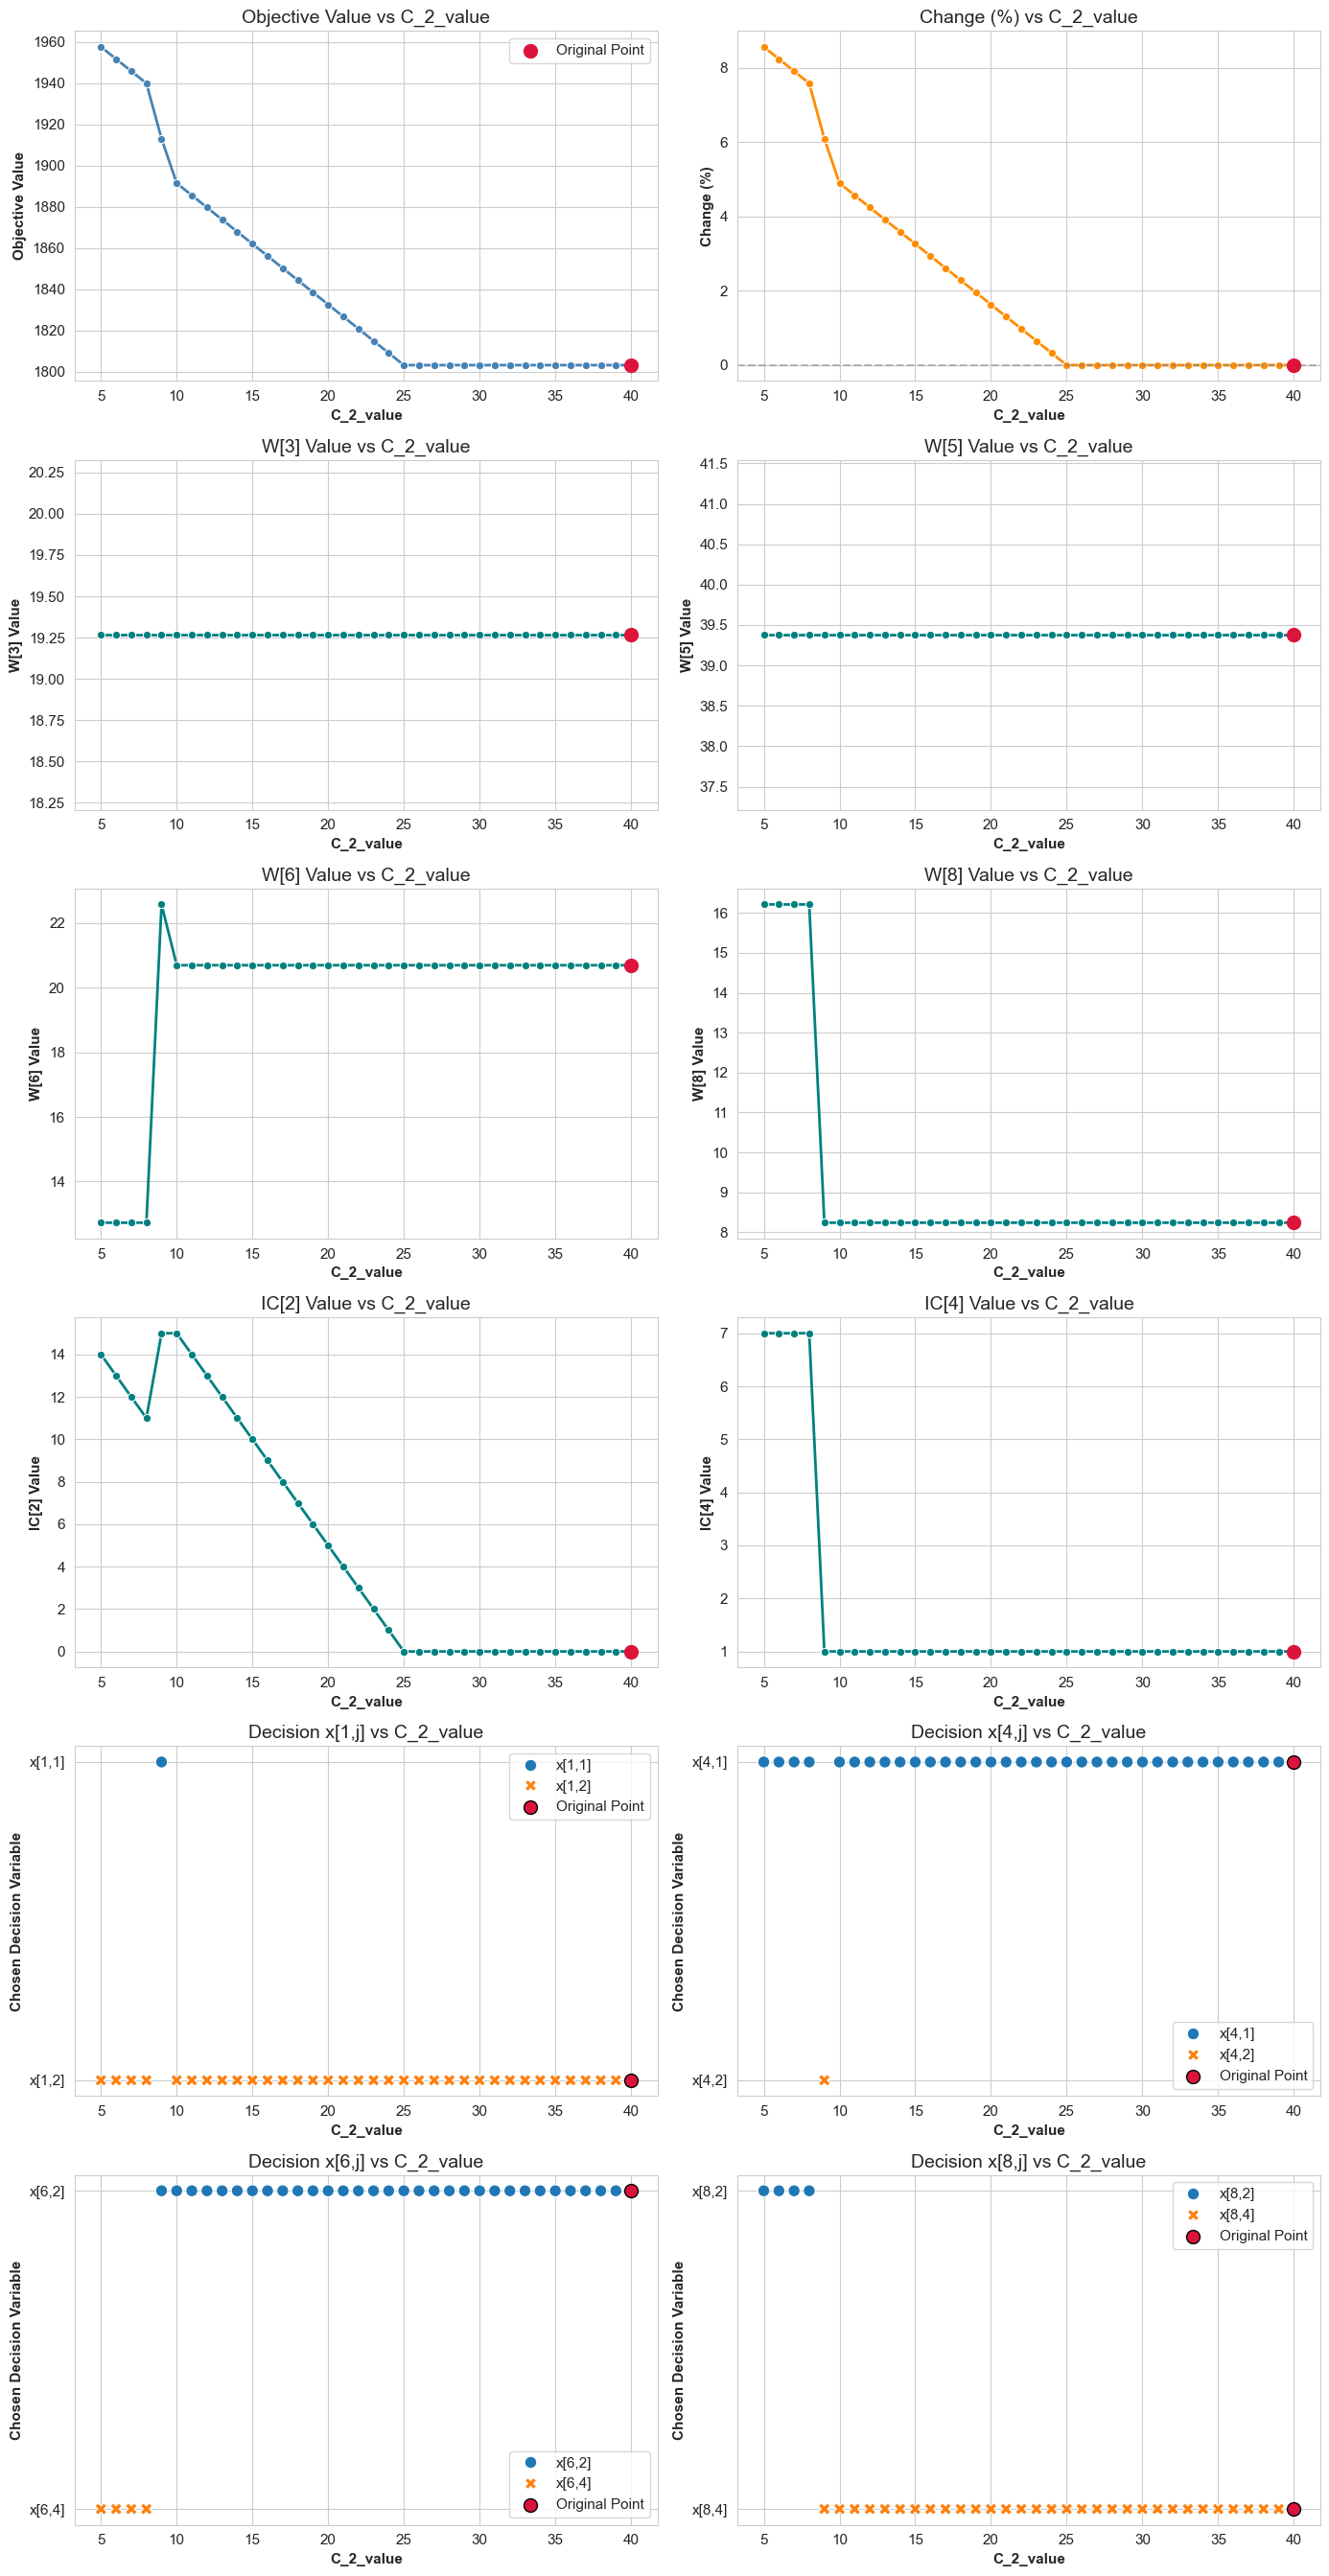

In [45]:
# Style settings
sns.set_style("whitegrid")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelweight': 'bold',
    'axes.titlesize': 14
})

# Colors & markers
main_color = 'steelblue'
highlight_color = 'crimson'
marker_style = 'o'
marker_size = 6
highlight_size = 100

# Original point index
orig_idx = 0
orig_x = df_final['C_2_value'].iloc[orig_idx]
orig_obj = df_final['objective'].iloc[orig_idx]

# Calculate percentage change
df_final['pct_change'] = ((df_final['objective'] - orig_obj) / orig_obj) * 100

# Base continuous plots
variables = [
    ('objective', 'Objective Value'),
    ('pct_change', 'Change (%)'),
]

# Add W[i] and IC[i] variables if present
for col in ['W[3]', 'W[5]', 'W[6]', 'W[8]', 'IC[2]', 'IC[4]']:
    if col in df_final.columns:
        variables.append((col, f'{col} Value'))

# Decision groups to check
decision_groups = {
    'Decision x[1,j]': ['x[1,1]', 'x[1,2]'],
    'Decision x[4,j]': ['x[4,1]', 'x[4,2]'],
    'Decision x[6,j]': ['x[6,2]', 'x[6,4]'],
    'Decision x[7,j]': ['x[7,2]', 'x[7,3]'],
    'Decision x[8,j]': ['x[8,2]', 'x[8,4]'],
}

# Filter valid decision groups
decision_plots = []
for label, cols in decision_groups.items():
    if all(col in df_final.columns for col in cols):
        decision_plots.append((cols, label))
        variables.append((label, 'Chosen Decision'))

# Layout
num_plots = len(variables)
cols = 2
rows = math.ceil(num_plots / cols)

# Plotting
plt.figure(figsize=(7 * cols, 4.5 * rows))

for i, (var, ylabel) in enumerate(variables, 1):
    plt.subplot(rows, cols, i)

    if var.startswith("Decision"):
        # Get correct group of columns
        for group_cols, label in decision_plots:
            if label == var:
                break

        # Prepare long-form DataFrame
        df_x = df_final[['C_2_value'] + group_cols].copy()
        df_x['Index'] = df_x.index
        df_long = df_x.melt(id_vars=['C_2_value', 'Index'],
                            value_vars=group_cols,
                            var_name='Decision', value_name='Chosen')
        df_long = df_long[df_long['Chosen'] == 1]

        # Plot switches
        sns.scatterplot(data=df_long, x='C_2_value', y='Decision',
                        hue='Decision', style='Decision', s=80)

        # Highlight original
        orig_dec = df_long[df_long['Index'] == orig_idx]
        plt.scatter(orig_dec['C_2_value'], orig_dec['Decision'],
                    color=highlight_color, s=highlight_size,
                    edgecolor='black', label='Original Point', zorder=5)

        plt.title(f'{label} vs C_2_value')
        plt.ylabel('Chosen Decision Variable')
        plt.xlabel('C_2_value')
        plt.legend()

    else:
        # Continuous line plots
        color = 'darkorange' if var == 'pct_change' else main_color
        if 'W[' in var or 'IC[' in var:
            color = 'teal'

        sns.lineplot(data=df_final, x='C_2_value', y=var,
                     marker=marker_style, color=color,
                     markersize=marker_size, linewidth=2)

        plt.scatter(orig_x, df_final[var].iloc[orig_idx],
                    color=highlight_color, s=highlight_size,
                    label='Original Point', zorder=5)

        if var == 'pct_change':
            plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

        plt.title(f'{ylabel} vs C_2_value')
        plt.xlabel('C_2_value')
        plt.ylabel(ylabel)

        if i == 1:
            plt.legend()

plt.tight_layout()
plt.show()


In [46]:
# Define target variables for sensitivity
target_vars = ['objective', 'W[3]', 'W[5]', 'W[6]', 'W[8]', 'IC[2]', 'IC[4]']
target_vars = [v for v in target_vars if v in df_final.columns]  # Filter only existing

if len(df_final) > 1 and target_vars:
    data = {
        'Variable': [],
        'Original Value': [],
        'Min Value': [],
        'Max Value': [],
        'Range': [],
        'Sensitivity (%)': []
    }

    for var in target_vars:
        original = df_final[var].iloc[0]
        min_val = df_final[var].min()
        max_val = df_final[var].max()
        range_val = max_val - min_val

        sensitivity = (abs(range_val) / original) * 100 if original != 0 else float('inf')

        data['Variable'].append(var)
        data['Original Value'].append(original)
        data['Min Value'].append(min_val)
        data['Max Value'].append(max_val)
        data['Range'].append(range_val)
        data['Sensitivity (%)'].append(sensitivity)

    comparison_df = pd.DataFrame(data)

    styled_df = comparison_df.style \
        .set_properties(**{'font-weight': 'bold'}, subset=['Variable']) \
        .background_gradient(cmap='YlOrRd', subset=['Sensitivity (%)']) \
        .format({
            'Original Value': '{:.4f}',
            'Min Value': '{:.4f}',
            'Max Value': '{:.4f}',
            'Range': '{:.4f}',
            'Sensitivity (%)': '{:.2f}%'
        })

    print("\n📊 Sensitivity Analysis Summary:")
    display(styled_df)



📊 Sensitivity Analysis Summary:


pandas\io\formats\style.py:3811: RuntimeWarning: invalid value encountered in scalar multiply
  norm = _matplotlib.colors.Normalize(smin - (rng * low), smax + (rng * high))


,Variable,Original Value,Min Value,Max Value,Range,Sensitivity (%)
0,objective,1803.2706,1803.2706,1957.5633,154.2927,8.56%
1,W[3],19.2671,19.2671,19.2671,0.0000,0.00%
2,W[5],39.3789,39.3789,39.3789,0.0000,0.00%
3,W[6],20.6958,12.7240,22.5777,9.8537,47.61%
4,W[8],8.2408,8.2408,16.2126,7.9718,96.74%
5,IC[2],0.0000,0.0000,15.0000,15.0000,inf%
6,IC[4],1.0000,1.0000,7.0000,6.0000,600.00%


<h2> Part D: Sensitivity Analysis on C[3]

In [47]:
model.C[2] = original_C_2_value  # Reset to original value

In [48]:
C_3_values = [round(v * 1, 2) for v in range(5, 61)]
C_3_values.remove(52)  # Gives values from 5.0 to 80.0 in 0.5 steps
results = []
C_3_values.insert(0, original_C_3_value)  # Append the original value to the list
# Loop through each value for C[3]
for val in C_3_values :
    model.C[3] = val  # Update the parameter

    # Solve the model
    solver = pyo.SolverFactory('glpk')
    result = solver.solve(model)

    # Record objective
    obj_val = value(model.obj)

    # Record decision variable x[i,j]
    x_vals = {(i, j): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i, j].value >0}
    x_vals = {(f'x[{i},{j}]'): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i,j].value>0}
    W_vals = {(f'W[{i}]'): value(model.W[i]) for i in model.i}
    IC_vals = {(f'IC[{j}]'): value(model.IC[j]) for j in model.j}
    s_vals = {(f's[{i}]'): value(model.s[i]) for i in model.i}
    C_vals = {(f'C[{j}]'): value(model.C[j]) for j in model.j}

    # Flatten results into one row per (o3_val)
    row = {
        'C_3_value': val,
        'objective': obj_val,
        'x_values': x_vals,
        'W_vals': W_vals,
        'IC_vals': IC_vals,
        's_vals': s_vals,
        'C_vals': C_vals
    }
    results.append(row)

# Convert to DataFrame
df_results = pd.DataFrame(results)

# Expand x_values into columns
df_x = df_results['x_values'].apply(pd.Series)
df_W = df_results['W_vals'].apply(pd.Series)
df_IC = df_results['IC_vals'].apply(pd.Series)
df_s = df_results['s_vals'].apply(pd.Series)
df_C = df_results['C_vals'].apply(pd.Series)
df_final = pd.concat([df_results[['C_3_value', 'objective']], df_x,df_W,df_IC,df_C], axis=1)


In [49]:
display(df_final)

,C_3_value,objective,"x[1,2]","x[2,4]","x[3,3]","x[4,1]","x[5,3]","x[6,2]","x[7,3]","x[8,4]",...,W[7],W[8],IC[1],IC[2],IC[3],IC[4],C[1],C[2],C[3],C[4]
0,52,1803.270601,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,8.240835,0.0,0.0,0.0,1.0,57,40,52,30
1,5,2100.357367,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,32.0,1.0,57,40,5,30
2,6,2091.493120,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,31.0,1.0,57,40,6,30
3,7,2082.628873,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,30.0,1.0,57,40,7,30
4,8,2073.764626,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,29.0,1.0,57,40,8,30
5,9,2064.900380,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,28.0,1.0,57,40,9,30
6,10,2056.036133,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,27.0,1.0,57,40,10,30
7,11,2047.171886,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,26.0,1.0,57,40,11,30
8,12,2038.307639,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,25.0,1.0,57,40,12,30
9,13,2029.443393,NaN,1.0,1.0,1.0,1.0,1.0,NaN,1.0,...,0.0,8.240835,0.0,0.0,24.0,1.0,57,40,13,30


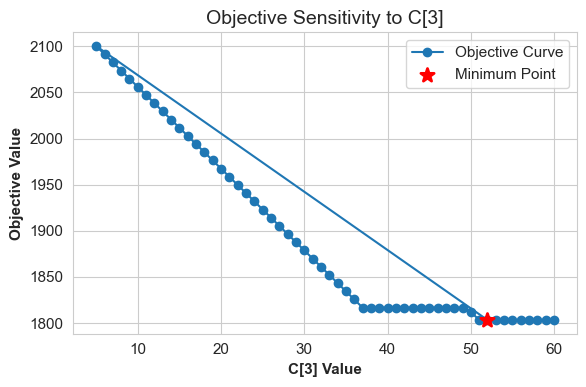

In [50]:
plt.figure(figsize=(6, 4))

# Line plot with label
plt.plot(df_final['C_3_value'], df_final['objective'], marker='o', label='Objective Curve', zorder=1)


plt.scatter(
    x=df_final['C_3_value'].iloc[0], y=df_final['objective'].iloc[0],
    color='red', s=100, linewidths=2,marker='*',
    label='Minimum Point', zorder=3
)

plt.xlabel('C[3] Value')
plt.ylabel('Objective Value')
plt.title('Objective Sensitivity to C[3]')
plt.grid(True, zorder=0)
plt.legend()
plt.tight_layout()
plt.show()

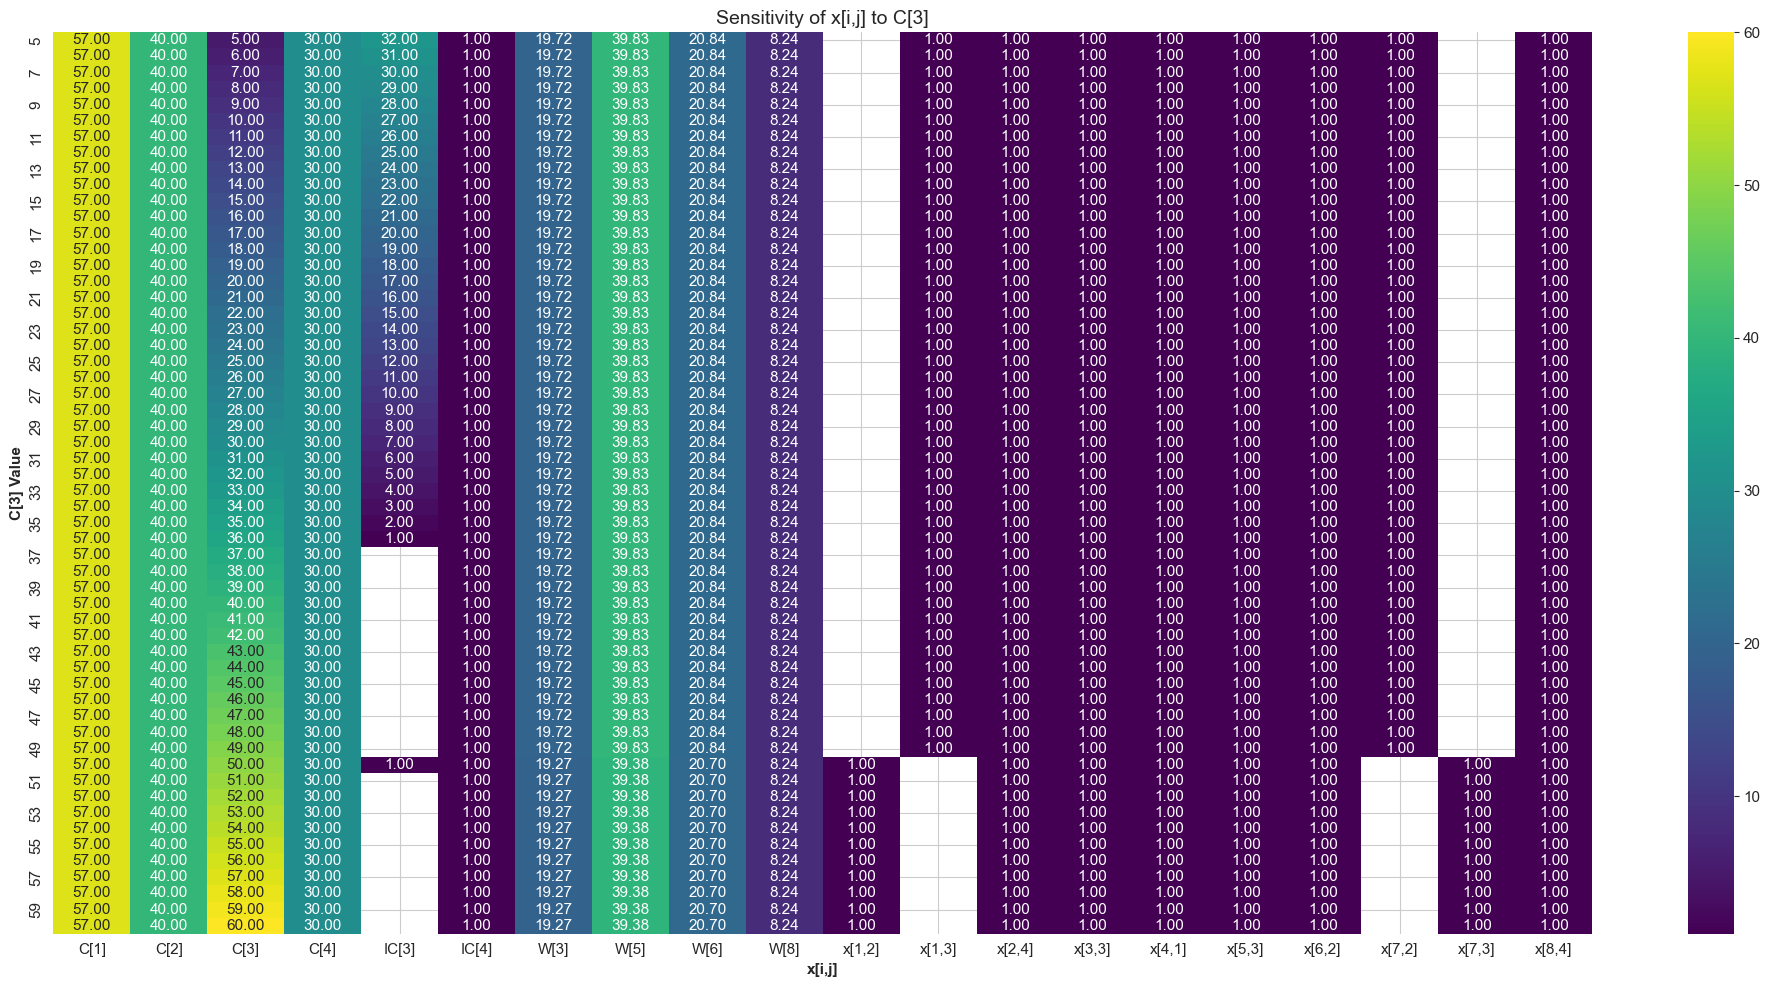

In [51]:
# Convert wide-form df to long-form
df_long = df_final.melt(id_vars=['C_3_value', 'objective'], var_name='(i,j)', value_name='x_val')

# Filter only x variables that changed meaningfully (optional)
df_long = df_long[df_long['x_val'].abs() > 1e-3]

# Heatmap of decision variable changes
pivot = df_long.pivot(index='C_3_value', columns='(i,j)', values='x_val')
plt.figure(figsize=(20, 10))
sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f")
plt.title("Sensitivity of x[i,j] to C[3]")
plt.xlabel("x[i,j]")
plt.ylabel("C[3] Value")
plt.tight_layout()
plt.show()

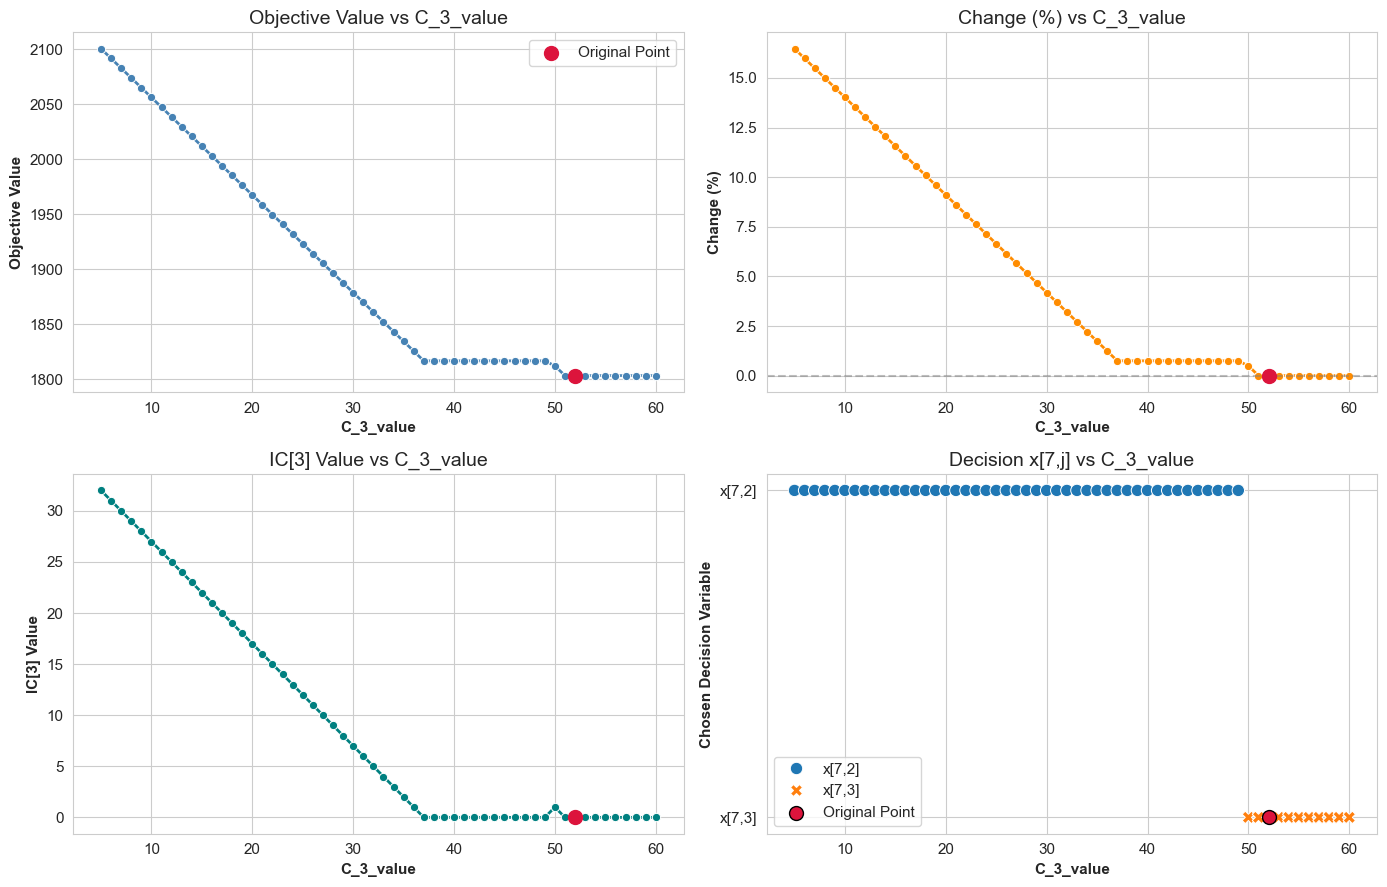

In [52]:
# Style settings
sns.set_style("whitegrid")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelweight': 'bold',
    'axes.titlesize': 14
})

# Colors & markers
main_color = 'steelblue'
highlight_color = 'crimson'
marker_style = 'o'
marker_size = 6
highlight_size = 100

# Original point index
orig_idx = 0
orig_x = df_final['C_3_value'].iloc[orig_idx]
orig_obj = df_final['objective'].iloc[orig_idx]

# Calculate percentage change
df_final['pct_change'] = ((df_final['objective'] - orig_obj) / orig_obj) * 100

# Base continuous plots
variables = [
    ('objective', 'Objective Value'),
    ('pct_change', 'Change (%)'),
]

# Add W[i] and IC[i] variables if present
for col in [ 'IC[3]']:
    if col in df_final.columns:
        variables.append((col, f'{col} Value'))

# Decision groups to check
decision_groups = {
    'Decision x[1,j]': ['x[1,1]', 'x[1,2]'],
    'Decision x[7,j]': ['x[7,2]', 'x[7,3]'],
}

# Filter valid decision groups
decision_plots = []
for label, cols in decision_groups.items():
    if all(col in df_final.columns for col in cols):
        decision_plots.append((cols, label))
        variables.append((label, 'Chosen Decision'))

# Layout
num_plots = len(variables)
cols = 2
rows = math.ceil(num_plots / cols)

# Plotting
plt.figure(figsize=(7 * cols, 4.5 * rows))

for i, (var, ylabel) in enumerate(variables, 1):
    plt.subplot(rows, cols, i)

    if var.startswith("Decision"):
        # Get correct group of columns
        for group_cols, label in decision_plots:
            if label == var:
                break

        # Prepare long-form DataFrame
        df_x = df_final[['C_3_value'] + group_cols].copy()
        df_x['Index'] = df_x.index
        df_long = df_x.melt(id_vars=['C_3_value', 'Index'],
                            value_vars=group_cols,
                            var_name='Decision', value_name='Chosen')
        df_long = df_long[df_long['Chosen'] == 1]

        # Plot switches
        sns.scatterplot(data=df_long, x='C_3_value', y='Decision',
                        hue='Decision', style='Decision', s=80)

        # Highlight original
        orig_dec = df_long[df_long['Index'] == orig_idx]
        plt.scatter(orig_dec['C_3_value'], orig_dec['Decision'],
                    color=highlight_color, s=highlight_size,
                    edgecolor='black', label='Original Point', zorder=5)

        plt.title(f'{label} vs C_3_value')
        plt.ylabel('Chosen Decision Variable')
        plt.xlabel('C_3_value')
        plt.legend()

    else:
        # Continuous line plots
        color = 'darkorange' if var == 'pct_change' else main_color
        if 'W[' in var or 'IC[' in var:
            color = 'teal'

        sns.lineplot(data=df_final, x='C_3_value', y=var,
                     marker=marker_style, color=color,
                     markersize=marker_size, linewidth=2)

        plt.scatter(orig_x, df_final[var].iloc[orig_idx],
                    color=highlight_color, s=highlight_size,
                    label='Original Point', zorder=5)

        if var == 'pct_change':
            plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

        plt.title(f'{ylabel} vs C_3_value')
        plt.xlabel('C_3_value')
        plt.ylabel(ylabel)

        if i == 1:
            plt.legend()

plt.tight_layout()
plt.show()


In [53]:
# Define target variables for sensitivity
target_vars = ['objective', 'IC[3]']
target_vars = [v for v in target_vars if v in df_final.columns]  # Filter only existing

if len(df_final) > 1 and target_vars:
    data = {
        'Variable': [],
        'Original Value': [],
        'Min Value': [],
        'Max Value': [],
        'Range': [],
        'Sensitivity (%)': []
    }

    for var in target_vars:
        original = df_final[var].iloc[0]
        min_val = df_final[var].min()
        max_val = df_final[var].max()
        range_val = max_val - min_val

        sensitivity = (abs(range_val) / original) * 100 if original != 0 else float('inf')

        data['Variable'].append(var)
        data['Original Value'].append(original)
        data['Min Value'].append(min_val)
        data['Max Value'].append(max_val)
        data['Range'].append(range_val)
        data['Sensitivity (%)'].append(sensitivity)

    comparison_df = pd.DataFrame(data)

    styled_df = comparison_df.style \
        .set_properties(**{'font-weight': 'bold'}, subset=['Variable']) \
        .background_gradient(cmap='YlOrRd', subset=['Sensitivity (%)']) \
        .format({
            'Original Value': '{:.4f}',
            'Min Value': '{:.4f}',
            'Max Value': '{:.4f}',
            'Range': '{:.4f}',
            'Sensitivity (%)': '{:.2f}%'
        })

    print("\n📊 Sensitivity Analysis Summary:")
    display(styled_df)



📊 Sensitivity Analysis Summary:


pandas\io\formats\style.py:3811: RuntimeWarning: invalid value encountered in scalar multiply
  norm = _matplotlib.colors.Normalize(smin - (rng * low), smax + (rng * high))


,Variable,Original Value,Min Value,Max Value,Range,Sensitivity (%)
0,objective,1803.2706,1803.2706,2100.3574,297.0868,16.47%
1,IC[3],0.0000,0.0000,32.0000,32.0000,inf%


<h2> Part G: Sensitivity Analysis on a[6]

In [54]:
model.C[3] = original_C_3_value  # Reset to original value

In [55]:
a_6_values = [round(v * 0.1, 2) for v in range(10, 51)]  # Gives values from 5.0 to 80.0 in 0.5 steps
results = []
a_6_values.insert(0, original_a_6_value)  # Append the original value to the list
# Loop through each value for a[6]
for val in a_6_values :
    model.a[6] = val  # Update the parameter

    # Solve the model
    solver = pyo.SolverFactory('glpk')
    result = solver.solve(model)

    # Record objective
    obj_val = value(model.obj)

    # Record decision variable x[i,j]
    x_vals = {(i, j): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i, j].value >0}
    x_vals = {(f'x[{i},{j}]'): value(model.X[i, j]) for i in model.i for j in model.j if model.X[i,j].value>0}
    W_vals = {(f'W[{i}]'): value(model.W[i]) for i in model.i}
    IC_vals = {(f'IC[{j}]'): value(model.IC[j]) for j in model.j}
    s_vals = {(f's[{i}]'): value(model.s[i]) for i in model.i}
    C_vals = {(f'C[{j}]'): value(model.C[j]) for j in model.j}

    # Flatten results into one row per (o3_val)
    row = {
        'a_6_value': val,
        'objective': obj_val,
        'x_values': x_vals,
        'W_vals': W_vals,
        'IC_vals': IC_vals,
        's_vals': s_vals,
        'C_vals': C_vals
    }
    results.append(row)

# Convert to DataFrame
df_results = pd.DataFrame(results)

# Expand x_values into columns
df_x = df_results['x_values'].apply(pd.Series)
df_W = df_results['W_vals'].apply(pd.Series)
df_IC = df_results['IC_vals'].apply(pd.Series)
df_s = df_results['s_vals'].apply(pd.Series)
df_C = df_results['C_vals'].apply(pd.Series)
df_final = pd.concat([df_results[['a_6_value', 'objective']], df_x,df_W], axis=1)


In [56]:
display(df_final)

,a_6_value,objective,"x[1,2]","x[2,4]","x[3,3]","x[4,1]","x[5,3]","x[6,2]","x[7,3]","x[8,4]",W[1],W[2],W[3],W[4],W[5],W[6],W[7],W[8]
0,2.11799,1803.270601,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,20.695821,0.0,8.240835
1,1.00000,1814.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.813811,0.0,8.240835
2,1.10000,1813.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.713811,0.0,8.240835
3,1.20000,1812.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.613811,0.0,8.240835
4,1.30000,1811.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.513811,0.0,8.240835
5,1.40000,1810.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.413811,0.0,8.240835
6,1.50000,1809.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.313811,0.0,8.240835
7,1.60000,1808.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.213811,0.0,8.240835
8,1.70000,1807.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.113811,0.0,8.240835
9,1.80000,1806.450504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,19.267057,0.0,39.378891,21.013811,0.0,8.240835


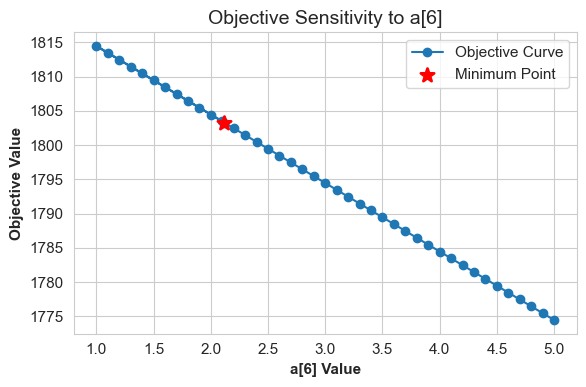

In [57]:
plt.figure(figsize=(6, 4))

# Line plot with label
plt.plot(df_final['a_6_value'], df_final['objective'], marker='o', label='Objective Curve', zorder=1)


plt.scatter(
    x=df_final['a_6_value'].iloc[0], y=df_final['objective'].iloc[0],
    color='red', s=100, linewidths=2,marker='*',
    label='Minimum Point', zorder=3
)

plt.xlabel('a[6] Value')
plt.ylabel('Objective Value')
plt.title('Objective Sensitivity to a[6]')
plt.grid(True, zorder=0)
plt.legend()
plt.tight_layout()
plt.show()

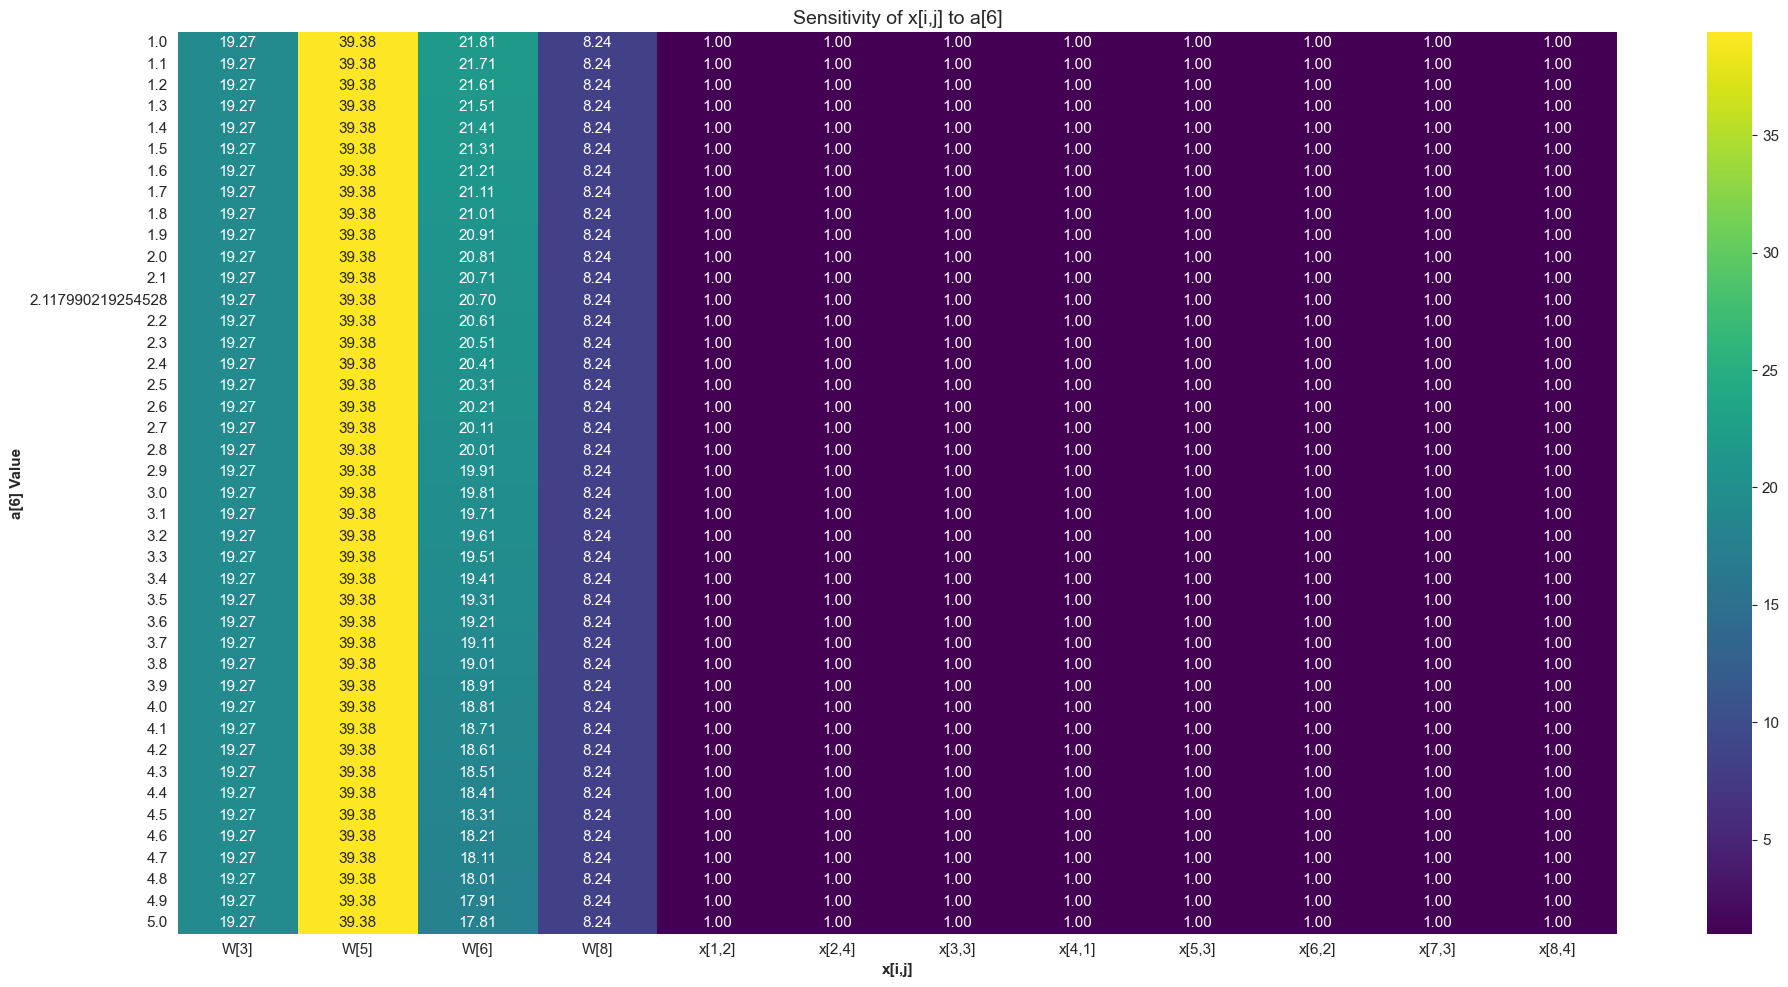

In [58]:
# Convert wide-form df to long-form
df_long = df_final.melt(id_vars=['a_6_value', 'objective'], var_name='(i,j)', value_name='x_val')

# Filter only x variables that changed meaningfully (optional)
df_long = df_long[df_long['x_val'].abs() > 1e-3]

# Heatmap of decision variable changes
pivot = df_long.pivot(index='a_6_value', columns='(i,j)', values='x_val')
plt.figure(figsize=(20, 10))
sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f")
plt.title("Sensitivity of x[i,j] to a[6]")
plt.xlabel("x[i,j]")
plt.ylabel("a[6] Value")
plt.tight_layout()
plt.show()

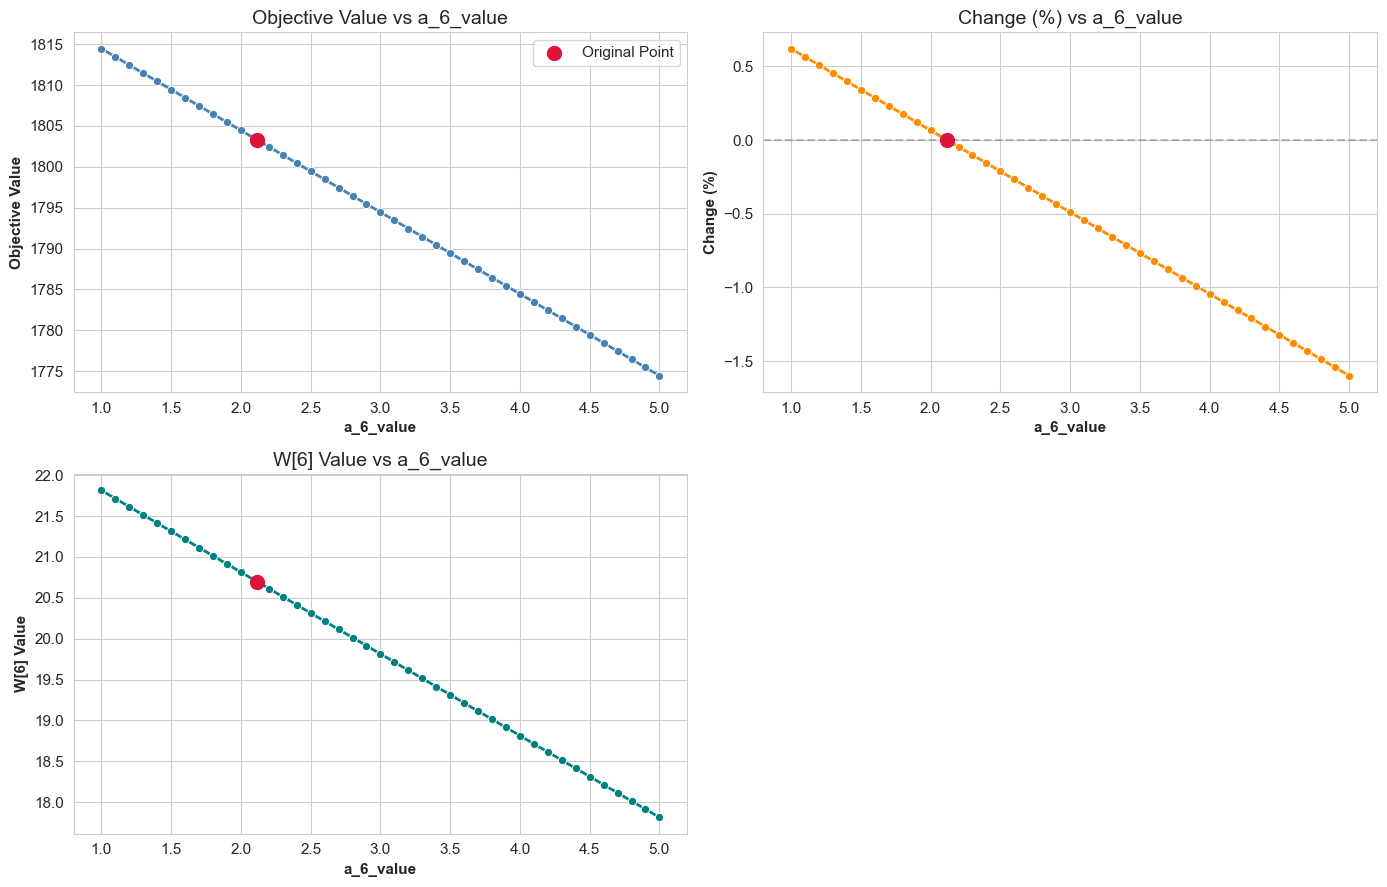

In [59]:
# Style settings
sns.set_style("whitegrid")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelweight': 'bold',
    'axes.titlesize': 14
})

# Colors & markers
main_color = 'steelblue'
highlight_color = 'crimson'
marker_style = 'o'
marker_size = 6
highlight_size = 100

# Original point index
orig_idx = 0
orig_x = df_final['a_6_value'].iloc[orig_idx]
orig_obj = df_final['objective'].iloc[orig_idx]

# Calculate percentage change
df_final['pct_change'] = ((df_final['objective'] - orig_obj) / orig_obj) * 100

# Base continuous plots
variables = [
    ('objective', 'Objective Value'),
    ('pct_change', 'Change (%)'),
]

# Add W[i] and IC[i] variables if present
for col in [ 'W[6]']:
    if col in df_final.columns:
        variables.append((col, f'{col} Value'))

# Decision groups to check
decision_groups = {
}

# Filter valid decision groups
decision_plots = []
for label, cols in decision_groups.items():
    if all(col in df_final.columns for col in cols):
        decision_plots.append((cols, label))
        variables.append((label, 'Chosen Decision'))

# Layout
num_plots = len(variables)
cols = 2
rows = math.ceil(num_plots / cols)

# Plotting
plt.figure(figsize=(7 * cols, 4.5 * rows))

for i, (var, ylabel) in enumerate(variables, 1):
    plt.subplot(rows, cols, i)

    if var.startswith("Decision"):
        # Get correct group of columns
        for group_cols, label in decision_plots:
            if label == var:
                break

        # Prepare long-form DataFrame
        df_x = df_final[['a_6_value'] + group_cols].copy()
        df_x['Index'] = df_x.index
        df_long = df_x.melt(id_vars=['a_6_value', 'Index'],
                            value_vars=group_cols,
                            var_name='Decision', value_name='Chosen')
        df_long = df_long[df_long['Chosen'] == 1]

        # Plot switches
        sns.scatterplot(data=df_long, x='a_6_value', y='Decision',
                        hue='Decision', style='Decision', s=80)

        # Highlight original
        orig_dec = df_long[df_long['Index'] == orig_idx]
        plt.scatter(orig_dec['a_6_value'], orig_dec['Decision'],
                    color=highlight_color, s=highlight_size,
                    edgecolor='black', label='Original Point', zorder=5)

        plt.title(f'{label} vs a_6_value')
        plt.ylabel('Chosen Decision Variable')
        plt.xlabel('a_6_value')
        plt.legend()

    else:
        # Continuous line plots
        color = 'darkorange' if var == 'pct_change' else main_color
        if 'W[' in var or 'IC[' in var:
            color = 'teal'

        sns.lineplot(data=df_final, x='a_6_value', y=var,
                     marker=marker_style, color=color,
                     markersize=marker_size, linewidth=2)

        plt.scatter(orig_x, df_final[var].iloc[orig_idx],
                    color=highlight_color, s=highlight_size,
                    label='Original Point', zorder=5)

        if var == 'pct_change':
            plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

        plt.title(f'{ylabel} vs a_6_value')
        plt.xlabel('a_6_value')
        plt.ylabel(ylabel)

        if i == 1:
            plt.legend()

plt.tight_layout()
plt.show()


In [60]:
# Define target variables for sensitivity
target_vars = ['objective', 'W[6]]']
target_vars = [v for v in target_vars if v in df_final.columns]  # Filter only existing

if len(df_final) > 1 and target_vars:
    data = {
        'Variable': [],
        'Original Value': [],
        'Min Value': [],
        'Max Value': [],
        'Range': [],
        'Sensitivity (%)': []
    }

    for var in target_vars:
        original = df_final[var].iloc[0]
        min_val = df_final[var].min()
        max_val = df_final[var].max()
        range_val = max_val - min_val

        sensitivity = (abs(range_val) / original) * 100 if original != 0 else float('inf')

        data['Variable'].append(var)
        data['Original Value'].append(original)
        data['Min Value'].append(min_val)
        data['Max Value'].append(max_val)
        data['Range'].append(range_val)
        data['Sensitivity (%)'].append(sensitivity)

    comparison_df = pd.DataFrame(data)

    styled_df = comparison_df.style \
        .set_properties(**{'font-weight': 'bold'}, subset=['Variable']) \
        .background_gradient(cmap='YlOrRd', subset=['Sensitivity (%)']) \
        .format({
            'Original Value': '{:.4f}',
            'Min Value': '{:.4f}',
            'Max Value': '{:.4f}',
            'Range': '{:.4f}',
            'Sensitivity (%)': '{:.2f}%'
        })

    print("\n📊 Sensitivity Analysis Summary:")
    display(styled_df)



📊 Sensitivity Analysis Summary:


,Variable,Original Value,Min Value,Max Value,Range,Sensitivity (%)
0,objective,1803.2706,1774.4505,1814.4505,40.0000,2.22%
